# Task 1 — Anti-Cheat Pre-Filter

## 1. Setup & Configuration

ตั้ง seed และใช้ Macro F₂ โดย outer CV เป็น 3 folds × 2 repeats และเลือก threshold ด้วย inner 3 folds
วางข้อมูลการแข่งขันใน `data/raw` ใต้โฟลเดอร์ notebook หรือตั้ง `TASK1_RAW_DIR` เป็น path ที่มี train.csv, test.csv และ datacard.txt
Run All จะสร้างผลใน `outputs` ใต้โฟลเดอร์ notebook สามารถตั้ง `TASK1_OUTPUT_DIR` เพื่อเปลี่ยนโฟลเดอร์ผล การสำรวจ combinations และ joint permutation ใช้เวลามากจึงเปิดตามต้องการในส่วน 4.3

### 1.1 Import libraries

In [55]:
from pathlib import Path
from importlib.metadata import version
import random
import sys

import numpy as np
import pandas as pd
from IPython.display import display

### 1.2 Seed และค่าตั้งต้น

In [56]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ID = "player_id"
TARGET = "is_cheater"
LABEL_NAMES = {0: "Legitimate", 1: "Cheater"}
METRIC = "macro_F2"
N_OUTER_FOLDS = 3
N_REPEATS = 2
N_INNER_FOLDS = 3

### 1.3 Project paths

In [ ]:
import os

cwd = Path.cwd().resolve()
roots = (cwd, *cwd.parents)
candidates = (
    path for root in roots
    for path in (root, root / "Thanawat" / "task1", root / "Task1",
                 root / "cpe-342-ml-kaggle-assemble" / "Thanawat" / "task1",
                 root / "CPE342-Kaggle" / "Task1")
)
TASK_DIR = next((path for path in candidates if (path / "Task1.ipynb").is_file()), cwd)
project_task = next(
    (root / "CPE342-Kaggle" / "Task1" for root in roots
     if (root / "CPE342-Kaggle" / "Task1" / "data" / "raw").is_dir()),
    TASK_DIR,
)
local_raw = TASK_DIR / "data" / "raw"
default_raw = local_raw if local_raw.is_dir() else project_task / "data" / "raw"
RAW_DIR = Path(os.environ.get("TASK1_RAW_DIR", str(default_raw))).expanduser().resolve()
OUTPUT_DIR = Path(os.environ.get("TASK1_OUTPUT_DIR", str(TASK_DIR / "outputs"))).expanduser().resolve()

### 1.4 ตรวจ Python และเวอร์ชันแพ็กเกจ

In [ ]:
print("Python:", sys.version.split()[0])
print("Interpreter:", sys.executable)
print("Output:", OUTPUT_DIR)
print("Raw data:", RAW_DIR)
print("Seed:", SEED, "| Metric:", METRIC)
display(pd.Series(
    {package: version(package) for package in
     ["numpy", "pandas", "scikit-learn", "lightgbm", "pyarrow"]},
    name="installed_version",
).to_frame())

## 2. Load Data

อ่าน `train.csv`, `test.csv` และ `datacard.txt` จาก `Task1/data/raw/` เก็บข้อมูลดิบไว้ใน `train_raw` และ `test_raw` โดยยังไม่เติม missing values, ลบแถว หรือสร้าง features

Test ใช้ตรวจโครงสร้างและสำหรับทำนายภายหลัง ไม่ใช้ฝึกโมเดล เลือก features หรือปรับ threshold

### 2.1 ตรวจไฟล์ที่ต้องใช้

In [59]:
DATA_FILES = {name: RAW_DIR / name for name in
              ["train.csv", "test.csv", "datacard.txt"]}
missing_files = [str(path) for path in DATA_FILES.values() if not path.is_file()]
if missing_files:
    raise FileNotFoundError("ยังไม่มีไฟล์: " + ", ".join(missing_files))

### 2.2 โหลด Train

In [60]:
train_raw = pd.read_csv(DATA_FILES["train.csv"], dtype={ID: "string"})

### 2.3 โหลด Test

In [61]:
test_raw = pd.read_csv(DATA_FILES["test.csv"], dtype={ID: "string"})

### 2.4 อ่าน Datacard

In [62]:
datacard = DATA_FILES["datacard.txt"].read_text(encoding="utf-8-sig")
print(datacard)

TASK 1: ANTI-CHEAT DETECTION

TARGET VARIABLE: is_cheater (Binary)
Binary classification: 0=Legitimate Player, 1=Cheater

FEATURES (31 features):

1. kill_death_ratio (float)
   Ratio of kills to deaths

2. headshot_percentage (float)
   Percentage of kills that are headshots[1]

3. win_rate (float)
   Percentage of matches won

4. accuracy_score (float)
   Overall shooting accuracy score

5. kill_consistency (float)
   Variance in kill performance (higher = more consistent)

6. reaction_time_ms (float)
   Average reaction time in milliseconds

7. account_age_days (float)
   Days since account creation

8. level (float)
   Current player level

9. level_progression_speed (float)
   Rate of level advancement

10. friend_network_size (float)
    Number of in-game friends

11. reports_received (float)
    Number of player reports received

12. device_changes_count (float)
    Frequency of device/hardware changes

13. input_consistency_score (float)
    Consistency of mouse/keyboard input 

### 2.5 ขนาดข้อมูล

In [63]:
display(pd.DataFrame({
    "rows": [len(train_raw), len(test_raw)],
    "columns": [train_raw.shape[1], test_raw.shape[1]],
}, index=["train", "test"]))

,rows,columns
train,104000,33
test,25889,32


## 3. Data Validation

ตรวจ schema, ชนิดข้อมูล, ID, target และค่าที่ขาดหายก่อนเริ่ม EDA

Target ที่หายต้องแยกจาก target `0` ห้ามเติมเป็นผู้เล่นปกติ แถวเหล่านี้ยังคงอยู่ใน `train_raw`; ส่วนฝึกและ validation ภายหลังจะใช้เฉพาะแถวที่มี label ส่วนค่าผิดช่วงหรือแถวซ้ำในรายงานนี้ยังไม่ถูกลบหรือแก้ไข

### 3.1 Helper สำหรับแจ้งข้อผิดพลาด

In [64]:
def require(condition, message):
    if not condition:
        raise ValueError(message)

### 3.2 ตรวจคอลัมน์ที่จำเป็น

In [65]:
require(not train_raw.empty and not test_raw.empty, "Train/Test ต้องไม่เป็นไฟล์ว่าง")
require(train_raw.columns.is_unique and test_raw.columns.is_unique, "ชื่อคอลัมน์ซ้ำ")
require(ID in train_raw and ID in test_raw, f"Train/Test ต้องมี {ID}")
require(TARGET in train_raw, f"Train ต้องมี {TARGET}")
require(TARGET not in test_raw, "Test ต้องไม่มี target")

### 3.3 ตรวจชื่อและลำดับ Predictors

In [66]:
feature_cols = [c for c in train_raw.columns if c not in {ID, TARGET}]
require(len(feature_cols) == 31, "Datacard ของ Task 1 ระบุ 31 predictors")
require(train_raw.drop(columns=TARGET).columns.tolist() == test_raw.columns.tolist(),
        "ชื่อหรือลำดับคอลัมน์ Train/Test ไม่ตรงกัน")

### 3.4 ตรวจ ID ภายในแต่ละชุด

In [67]:
for split_name, frame in [("train", train_raw), ("test", test_raw)]:
    ids = frame[ID]
    require(ids.notna().all() and ids.str.strip().ne("").all(),
            f"{split_name}: ID ว่าง")
    require(ids.is_unique, f"{split_name}: ID ซ้ำ")

### 3.5 ตรวจ ID ทับกันระหว่าง Train/Test

In [68]:
require(not set(train_raw[ID]).intersection(test_raw[ID]), "Train/Test มี ID ทับกัน")

### 3.6 ตรวจชนิดข้อมูลและ Infinity

In [69]:
for split_name, frame in [("train", train_raw), ("test", test_raw)]:
    non_numeric = [c for c in feature_cols
                   if not pd.api.types.is_numeric_dtype(frame[c])]
    require(not non_numeric, f"{split_name}: predictors ไม่ใช่ numeric: {non_numeric}")
    require(not np.isinf(frame[feature_cols].to_numpy(dtype=float)).any(),
            f"{split_name}: predictors มี infinity")

### 3.7 ตรวจ Target

In [70]:
require(pd.api.types.is_numeric_dtype(train_raw[TARGET]), "Target ต้องเป็น numeric")
labeled_mask = train_raw[TARGET].notna()
require(labeled_mask.any(), "Train ไม่มี target ที่ทราบค่าเลย")
require(set(train_raw.loc[labeled_mask, TARGET].unique()) == {0, 1},
        "Target ที่ทราบค่าต้องมีทั้ง 0 และ 1 และไม่มีค่าอื่น")

### 3.8 จำนวน Labels และ Target ที่หาย

In [71]:
# สรุป label โดยไม่แก้ไข train_raw
label_summary = pd.DataFrame({
    "rows": [
        int(train_raw[TARGET].eq(0).sum()),
        int(train_raw[TARGET].eq(1).sum()),
        int((~labeled_mask).sum()),
    ],
}, index=["Legitimate (0)", "Cheater (1)", "Missing target"])
label_summary["pct_of_raw_train"] = 100 * label_summary["rows"] / len(train_raw)
display(label_summary.round(2))

,rows,pct_of_raw_train
Legitimate (0),59091,56.82
Cheater (1),31725,30.50
Missing target,13184,12.68


### 3.9 ข้อมูลซ้ำและแถวที่ขาด Predictors ทั้งหมด

In [72]:
quality_summary = pd.DataFrame({
    "rows": [len(train_raw), len(test_raw)],
    "exact_duplicate_rows": [int(train_raw.duplicated().sum()),
                             int(test_raw.duplicated().sum())],
    "all_features_missing_rows": [int(train_raw[feature_cols].isna().all(axis=1).sum()),
                                  int(test_raw[feature_cols].isna().all(axis=1).sum())],
    "missing_feature_cells": [int(train_raw[feature_cols].isna().sum().sum()),
                              int(test_raw[feature_cols].isna().sum().sum())],
}, index=["train", "test"])
display(quality_summary)

,rows,exact_duplicate_rows,all_features_missing_rows,missing_feature_cells
train,104000,0,0,386163
test,25889,0,0,64190


### 3.10 Missing Values รายคอลัมน์

In [73]:
missing_summary = pd.DataFrame({
    "train_dtype": train_raw[feature_cols].dtypes.astype(str),
    "test_dtype": test_raw[feature_cols].dtypes.astype(str),
    "train_missing_count": train_raw[feature_cols].isna().sum(),
    "train_missing_pct": train_raw[feature_cols].isna().mean() * 100,
    "test_missing_count": test_raw[feature_cols].isna().sum(),
    "test_missing_pct": test_raw[feature_cols].isna().mean() * 100,
})
display(missing_summary.sort_values("train_missing_pct", ascending=False).round(2))

,train_dtype,test_dtype,train_missing_count,train_missing_pct,test_missing_count,test_missing_pct
survival_time_avg,float64,float64,25305,24.33,3380,13.06
weapon_switch_speed,float64,float64,25213,24.24,4009,15.49
avg_session_length_min,float64,float64,23895,22.98,408,1.58
movement_pattern_score,float64,float64,23324,22.43,2258,8.72
friend_network_size,float64,float64,23265,22.37,1227,4.74
reports_received,float64,float64,23193,22.30,3866,14.93
aiming_smoothness,float64,float64,21710,20.88,534,2.06
communication_rate,float64,float64,21402,20.58,2859,11.04
team_play_score,float64,float64,20235,19.46,2104,8.13
spray_control_score,float64,float64,17428,16.76,1442,5.57


### 3.11 กำหนดกฎตรวจช่วงค่า

In [74]:
# ตรวจเฉพาะช่วงที่มีความหมายชัดเจนจากคำอธิบาย feature
# NaN ไม่ถูกนับเป็นค่าผิดช่วง และรายงานนี้ยังไม่แก้ไขข้อมูล
range_rules = {
    "headshot_percentage": (0, 100),
    "win_rate": (0, 100),
    "night_play_ratio": (0, 1),
    "clutch_success_rate": (0, 1),
    "first_blood_rate": (0, 1),
    "utility_usage_rate": (0, 1),
}

### 3.12 จำนวนค่าที่อยู่นอกช่วง

In [75]:
range_rows = []
for column, (low, high) in range_rules.items():
    range_rows.append({
        "feature": column,
        "expected_range": f"[{low}, {high}]",
        "train_outside": int((train_raw[column].lt(low) | train_raw[column].gt(high)).sum()),
        "test_outside": int((test_raw[column].lt(low) | test_raw[column].gt(high)).sum()),
    })
range_summary = pd.DataFrame(range_rows).set_index("feature")
display(range_summary)

,expected_range,train_outside,test_outside
feature,,,
headshot_percentage,"[0, 100]",0,0
win_rate,"[0, 100]",0,0
night_play_ratio,"[0, 1]",0,0
clutch_success_rate,"[0, 1]",0,0
first_blood_rate,"[0, 1]",0,0
utility_usage_rate,"[0, 1]",0,0


### 3.13 อ่านผลการตรวจช่วงค่า

In [76]:
if range_summary[["train_outside", "test_outside"]].to_numpy().any():
    print("พบค่าผิดช่วง: ต้องตรวจที่มาใน EDA ก่อนตัดสินใจจัดการ")
else:
    print("ไม่พบค่าผิดช่วงตามกฎที่ตรวจ ไม่ได้หมายความว่าตรวจคุณภาพข้อมูลครบทุกกรณี")

ไม่พบค่าผิดช่วงตามกฎที่ตรวจ ไม่ได้หมายความว่าตรวจคุณภาพข้อมูลครบทุกกรณี


### 3.14 สรุปความพร้อมก่อน EDA

In [77]:
print(f"พร้อมเริ่ม EDA: {labeled_mask.sum():,} labeled Train rows, {len(feature_cols)} predictors")
print("ข้อมูลดิบยังคงเดิม ไม่มีการฝึกโมเดลหรือใช้ Test เลือกโมเดล")

พร้อมเริ่ม EDA: 90,816 labeled Train rows, 31 predictors
ข้อมูลดิบยังคงเดิม ไม่มีการฝึกโมเดลหรือใช้ Test เลือกโมเดล


## 4. Exploratory Data Analysis (EDA)

In [24]:
train_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 104000 entries, 0 to 103999
Data columns (total 33 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   player_id                104000 non-null  string 
 1   kill_death_ratio         93962 non-null   float64
 2   headshot_percentage      101187 non-null  float64
 3   win_rate                 98817 non-null   float64
 4   accuracy_score           103356 non-null  float64
 5   kill_consistency         94269 non-null   float64
 6   reaction_time_ms         95881 non-null   float64
 7   account_age_days         88983 non-null   float64
 8   level                    96586 non-null   float64
 9   level_progression_speed  95560 non-null   float64
 10  friend_network_size      80735 non-null   float64
 11  reports_received         80807 non-null   float64
 12  device_changes_count     100922 non-null  float64
 13  input_consistency_score  93841 non-null   float64
 14  avg_session_len

In [25]:
train_raw.describe()

,kill_death_ratio,headshot_percentage,win_rate,accuracy_score,kill_consistency,reaction_time_ms,account_age_days,level,level_progression_speed,friend_network_size,...,team_play_score,buy_decision_score,map_knowledge,clutch_success_rate,first_blood_rate,survival_time_avg,damage_per_round,utility_usage_rate,crosshair_placement,is_cheater
count,93962.000000,101187.000000,98817.000000,103356.000000,94269.000000,95881.000000,88983.000000,96586.000000,95560.000000,80735.000000,...,83765.000000,90856.000000,95872.000000,101450.000000,95872.000000,78695.000000,94541.000000,92406.000000,90686.000000,90816.000000
mean,4.737964,47.861135,71.361470,40.187533,0.648680,135.173335,495.253960,62.865924,0.364644,137.766954,...,0.644423,0.597196,0.689955,0.340039,0.323370,66.236919,95.561595,0.581238,0.882866,0.349333
std,1.517484,13.753128,13.995451,12.119357,0.150382,51.095458,350.934765,20.743244,1.595146,84.605042,...,0.152687,0.156247,0.132550,0.138680,0.120266,24.153446,29.431153,0.173201,0.041567,0.476762
min,0.500000,5.000000,16.384967,8.000000,0.250000,55.000000,1.005388,25.005696,0.002926,0.000000,...,0.380026,0.234664,0.460001,0.100014,0.096762,8.928568,13.291025,0.280003,0.800008,0.000000
25%,3.711771,38.270544,61.672293,31.707278,0.543608,99.553841,156.222168,44.905046,0.040625,64.000000,...,0.513008,0.466889,0.575166,0.219948,0.219374,45.225490,70.500706,0.431725,0.847859,0.000000
50%,4.566687,47.128207,71.137088,39.674507,0.652679,128.430912,479.877057,62.862321,0.081280,135.000000,...,0.644334,0.590739,0.689492,0.339828,0.322848,66.231507,95.077701,0.582196,0.882614,0.000000
75%,5.536477,56.653761,80.996094,48.111470,0.756085,162.476155,762.091007,80.772610,0.213961,206.000000,...,0.776870,0.727586,0.804669,0.459861,0.425521,87.220842,120.459663,0.731090,0.918024,1.000000
max,12.000000,95.000000,100.000000,85.000000,0.980000,714.445534,1499.649904,99.998795,80.028706,349.000000,...,0.909989,0.879999,0.919998,0.579990,0.539997,107.998675,147.998801,0.879995,0.959999,1.000000


In [26]:
train_raw.head(5)

,player_id,kill_death_ratio,headshot_percentage,win_rate,accuracy_score,kill_consistency,reaction_time_ms,account_age_days,level,level_progression_speed,...,team_play_score,buy_decision_score,map_knowledge,clutch_success_rate,first_blood_rate,survival_time_avg,damage_per_round,utility_usage_rate,crosshair_placement,is_cheater
0,P001337,5.176237,54.245482,85.662938,25.457845,0.774864,83.828120,261.721035,34.009104,0.022950,...,0.692063,0.834387,0.550694,0.491093,0.483104,73.476007,55.711383,0.790575,0.893005,0.0
1,P044854,6.510362,54.388554,99.174621,36.679574,0.813276,148.295650,1075.704820,72.863639,0.067318,...,0.616427,0.853019,0.556390,0.562038,NaN,NaN,NaN,0.793743,0.956779,0.0
2,P036798,5.457167,60.417905,100.000000,44.558707,0.720939,117.662956,1031.540114,99.075389,0.055238,...,NaN,0.362643,0.579663,0.129658,0.335847,40.784374,NaN,0.563563,0.868322,0.0
3,P079617,NaN,35.180729,67.756853,42.750853,0.379890,348.463623,525.534446,39.694695,0.028952,...,0.501457,0.398195,0.630693,0.512969,0.178991,60.185066,135.341158,NaN,0.938778,NaN
4,P093830,3.747774,31.777986,80.689833,26.820793,0.567326,351.819822,296.179584,72.817519,0.040610,...,0.548742,0.485381,0.578093,0.421014,0.154923,59.359891,127.075580,0.471941,0.837420,NaN


In [27]:
overview_evidence = pd.Series({
    "train_rows": len(train_raw),
    "predictors": len(feature_cols),
    "numeric_predictors": train_raw[feature_cols].select_dtypes(include="number").shape[1],
    "legitimate_rows": int(train_raw[TARGET].eq(0).sum()),
    "cheater_rows": int(train_raw[TARGET].eq(1).sum()),
    "missing_target_rows": int(train_raw[TARGET].isna().sum()),
    "predictors_with_missing": int(train_raw[feature_cols].isna().any().sum()),
}, name="value")
display(overview_evidence.to_frame())

,value
train_rows,104000
predictors,31
numeric_predictors,31
legitimate_rows,59091
cheater_rows,31725
missing_target_rows,13184
predictors_with_missing,31


### 4.1 Univariate


#### 4.1.1 ผลงานในการแข่งขัน (Performance)

In [28]:
performance_cols = [
    "kill_death_ratio",
    "headshot_percentage",
    "win_rate",
    "accuracy_score",
    "kill_consistency",
    "clutch_success_rate",
    "first_blood_rate",
    "survival_time_avg",
    "damage_per_round",
]

In [29]:
stats = train_raw[performance_cols].agg(["count", "mean", "median", "min", "max"]).T
stats["count"] = stats["count"].astype(int)
stats["missing_count"] = train_raw[performance_cols].isna().sum()
display(stats.round(3))

,count,mean,median,min,max,missing_count
kill_death_ratio,93962,4.738,4.567,0.500,12.000,10038
headshot_percentage,101187,47.861,47.128,5.000,95.000,2813
win_rate,98817,71.361,71.137,16.385,100.000,5183
accuracy_score,103356,40.188,39.675,8.000,85.000,644
kill_consistency,94269,0.649,0.653,0.250,0.980,9731
clutch_success_rate,101450,0.340,0.340,0.100,0.580,2550
first_blood_rate,95872,0.323,0.323,0.097,0.540,8128
survival_time_avg,78695,66.237,66.232,8.929,107.999,25305
damage_per_round,94541,95.562,95.078,13.291,147.999,9459


##### 4.1.1.1 Distribution ของ Cheater และ Legitimate

Matplotlib is building the font cache; this may take a moment.


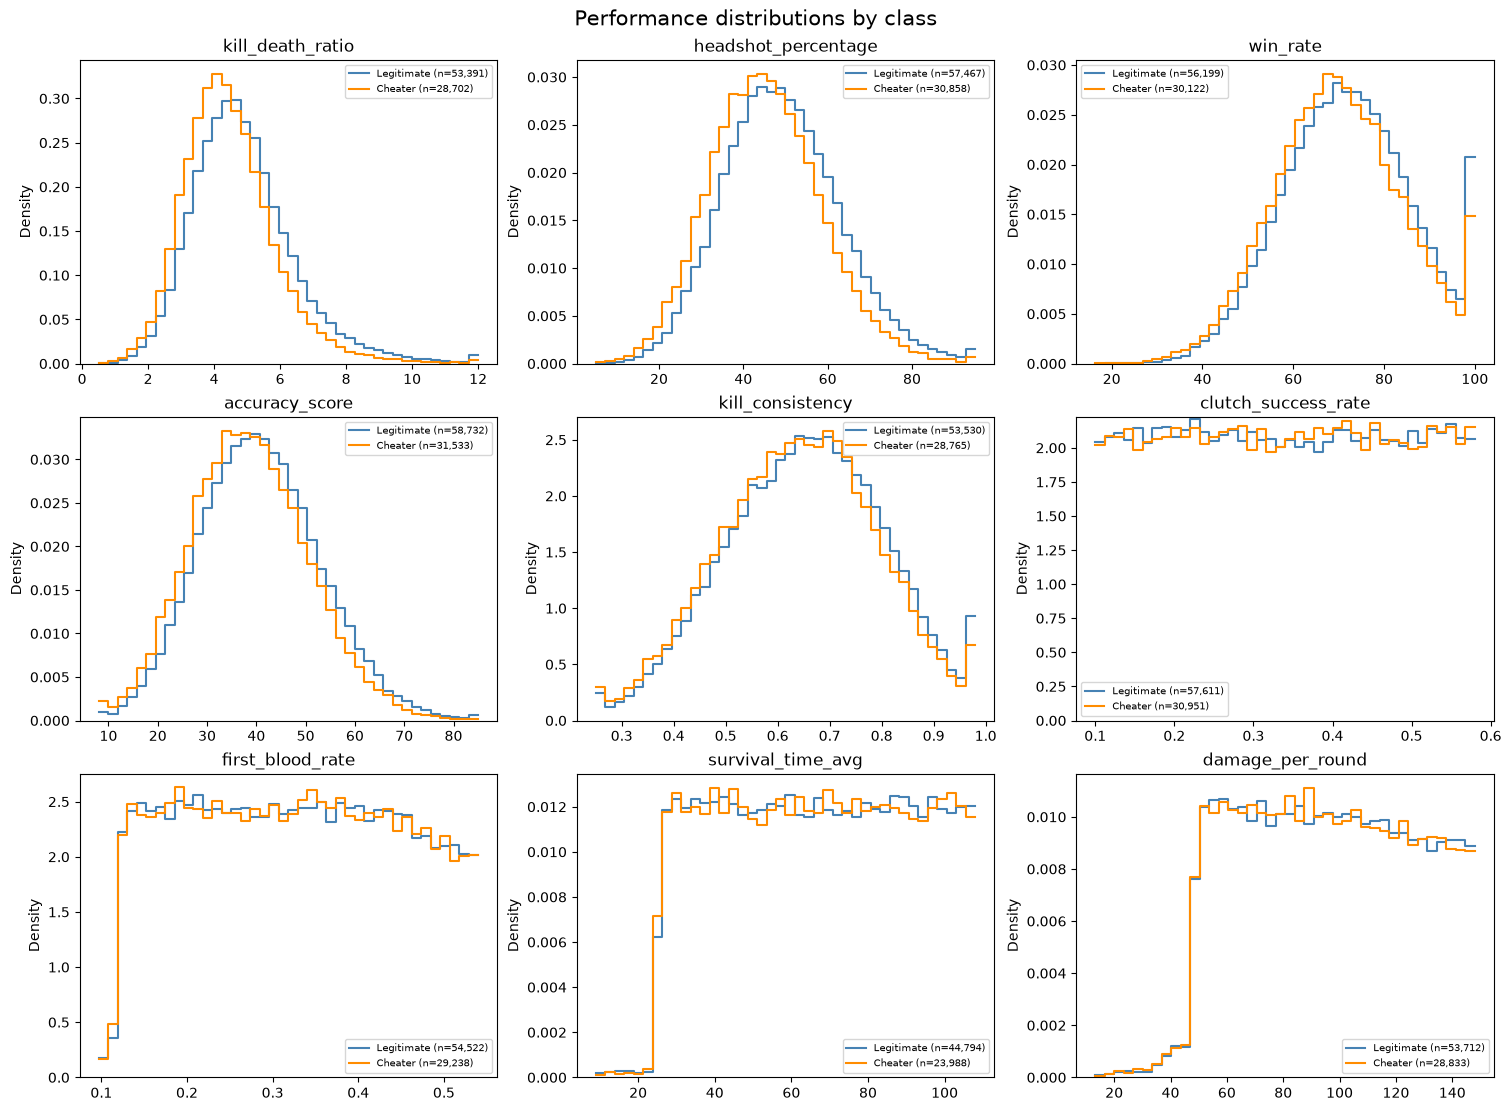

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

performance_labeled = train_raw.loc[train_raw[TARGET].isin(LABEL_NAMES)]
fig, axes = plt.subplots(3, 3, figsize=(15, 11), layout="constrained")
for ax, column in zip(axes.flat, performance_cols):
    bins = np.histogram_bin_edges(performance_labeled[column].dropna(), bins=40)
    for label, color in [(0, "steelblue"), (1, "darkorange")]:
        values = performance_labeled.loc[performance_labeled[TARGET].eq(label), column].dropna()
        sns.histplot(values, bins=bins, stat="density", element="step", fill=False,
                     color=color, label=f"{LABEL_NAMES[label]} (n={len(values):,})", ax=ax)
    ax.set(title=column, xlabel="", ylabel="Density")
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=7)
fig.suptitle("Performance distributions by class", fontsize=15)
plt.show()

##### 4.1.1.2 Boxplot ของ Cheater และ Legitimate

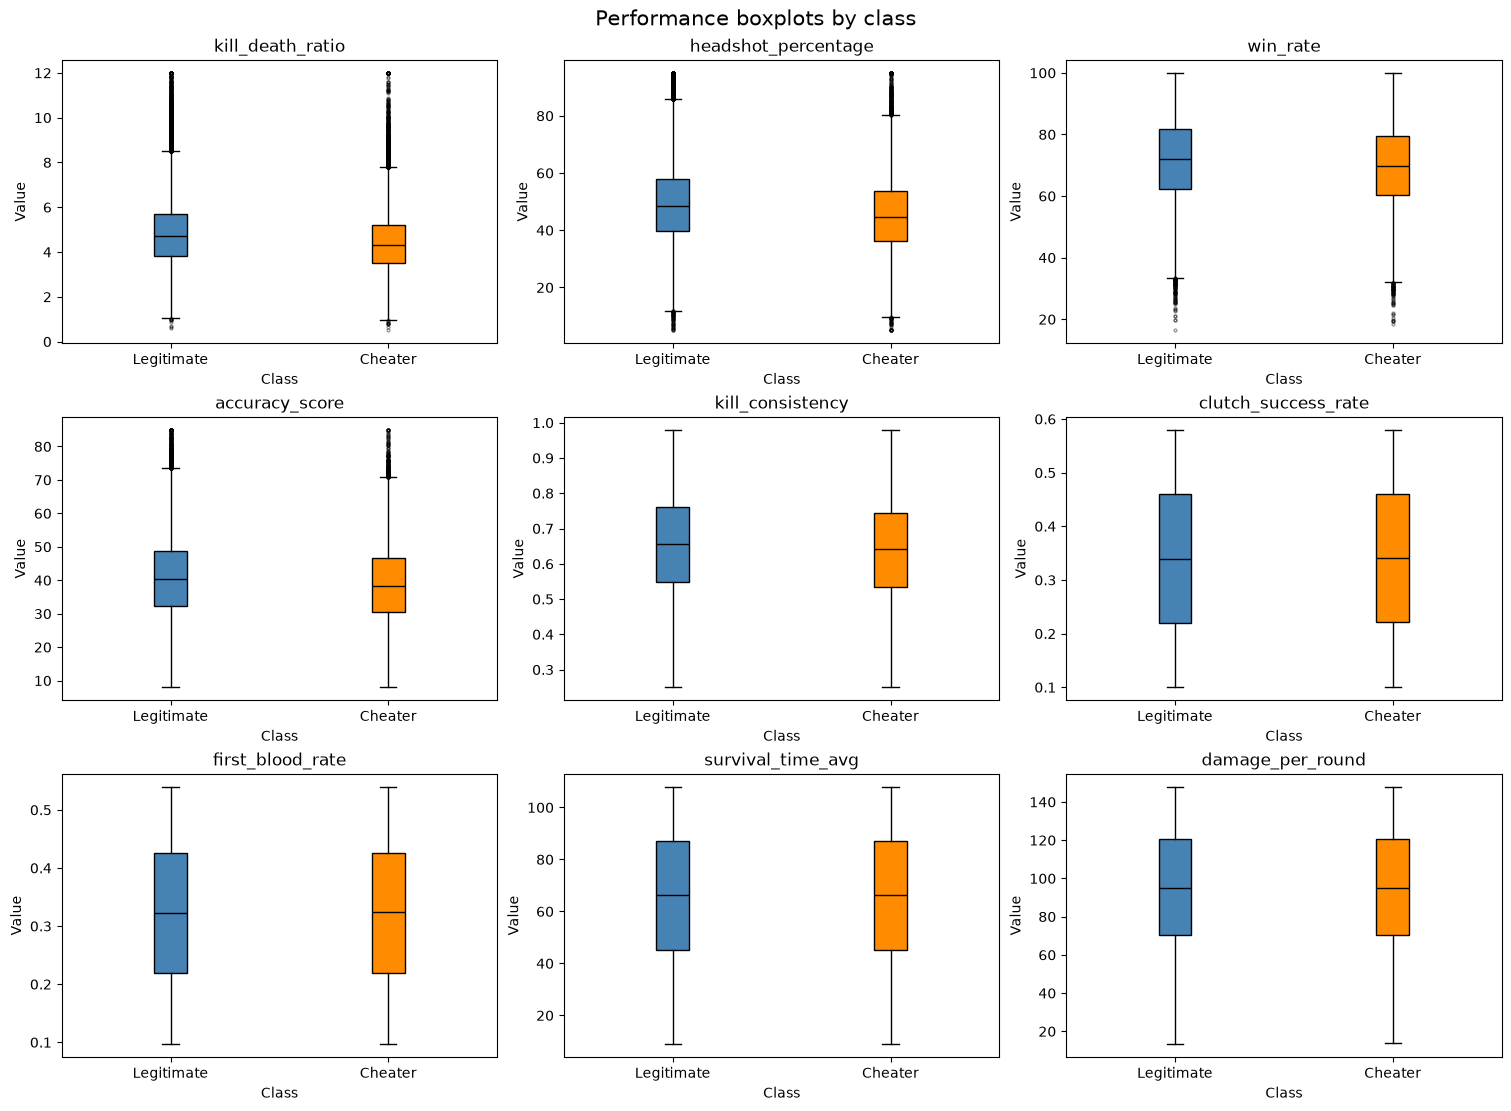

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11), layout="constrained")
for ax, column in zip(axes.flat, performance_cols):
    values = [performance_labeled.loc[performance_labeled[TARGET].eq(label), column].dropna()
              for label in [0, 1]]
    boxes = ax.boxplot(values, tick_labels=[LABEL_NAMES[0], LABEL_NAMES[1]],
                       patch_artist=True, medianprops={"color": "black"},
                       flierprops={"markersize": 2, "alpha": 0.4})
    for patch, color in zip(boxes["boxes"], ["steelblue", "darkorange"]):
        patch.set_facecolor(color)
    ax.set(title=column, xlabel="Class", ylabel="Value")
fig.suptitle("Performance boxplots by class", fontsize=15)
plt.show()

##### 4.1.1.3 Missing Rate ของ Cheater และ Legitimate

is_cheater,Legitimate,Cheater
kill_death_ratio,9.646,9.529
headshot_percentage,2.748,2.733
win_rate,4.894,5.053
accuracy_score,0.608,0.605
kill_consistency,9.411,9.330
clutch_success_rate,2.505,2.440
first_blood_rate,7.732,7.839
survival_time_avg,24.195,24.388
damage_per_round,9.103,9.116


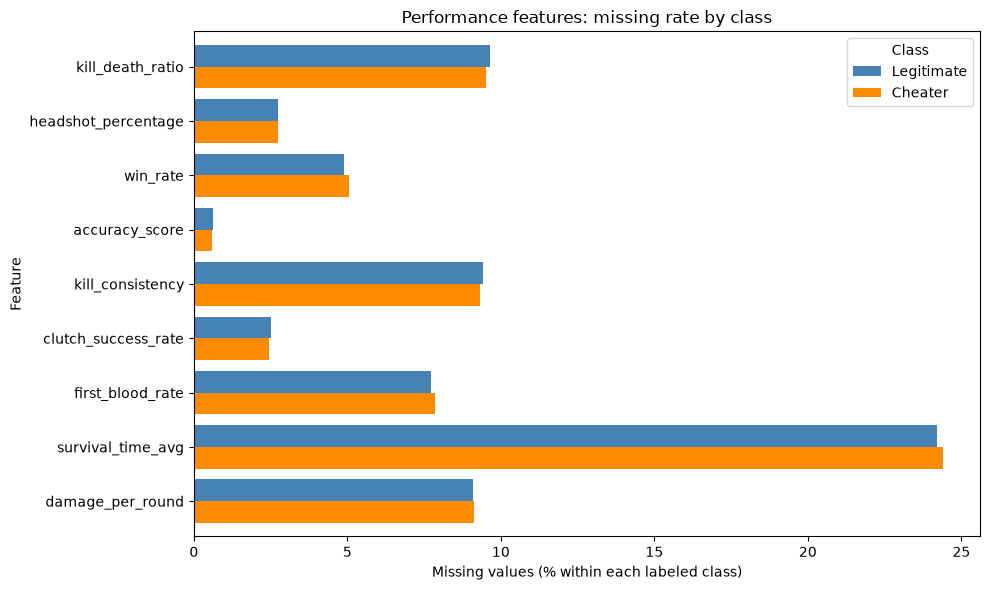

In [ ]:
performance_missing_pct = (
    performance_labeled[performance_cols].isna()
    .groupby(performance_labeled[TARGET]).mean().T.mul(100)
    .rename(columns=LABEL_NAMES)
)
display(performance_missing_pct.round(3))
ax = performance_missing_pct[[LABEL_NAMES[0], LABEL_NAMES[1]]].plot.barh(
    figsize=(10, 6), color=["steelblue", "darkorange"], width=0.8,
)
ax.set(xlabel="Missing values (% within each labeled class)", ylabel="Feature",
       title="Performance features: missing rate by class")
ax.invert_yaxis()
ax.legend(title="Class")
plt.tight_layout()
plt.show()

#### 4.1.2 Mechanics & Strategy

In [35]:
mechanics_cols = [
    "reaction_time_ms",
    "input_consistency_score",
    "weapon_switch_speed",
    "movement_pattern_score",
    "aiming_smoothness",
    "spray_control_score",
    "game_sense_score",
    "buy_decision_score",
    "map_knowledge",
    "utility_usage_rate",
    "crosshair_placement",
]

In [36]:
stats = train_raw[mechanics_cols].agg(["count", "mean", "median", "min", "max"]).T
stats["count"] = stats["count"].astype(int)
stats["missing_count"] = train_raw[mechanics_cols].isna().sum()
display(stats.round(3))

,count,mean,median,min,max,missing_count
reaction_time_ms,95881,135.173,128.431,55.000,714.446,8119
input_consistency_score,93841,0.740,0.741,0.381,0.950,10159
weapon_switch_speed,78787,0.634,0.631,0.270,0.910,25213
movement_pattern_score,80676,0.715,0.715,0.313,0.940,23324
aiming_smoothness,82290,0.834,0.844,0.323,1.000,21710
spray_control_score,86572,0.793,0.800,0.350,1.000,17428
game_sense_score,101239,0.819,0.821,0.407,1.000,2761
buy_decision_score,90856,0.597,0.591,0.235,0.880,13144
map_knowledge,95872,0.690,0.689,0.460,0.920,8128
utility_usage_rate,92406,0.581,0.582,0.280,0.880,11594


##### 4.1.2.1 Distribution ของ Cheater และ Legitimate

Matplotlib is building the font cache; this may take a moment.


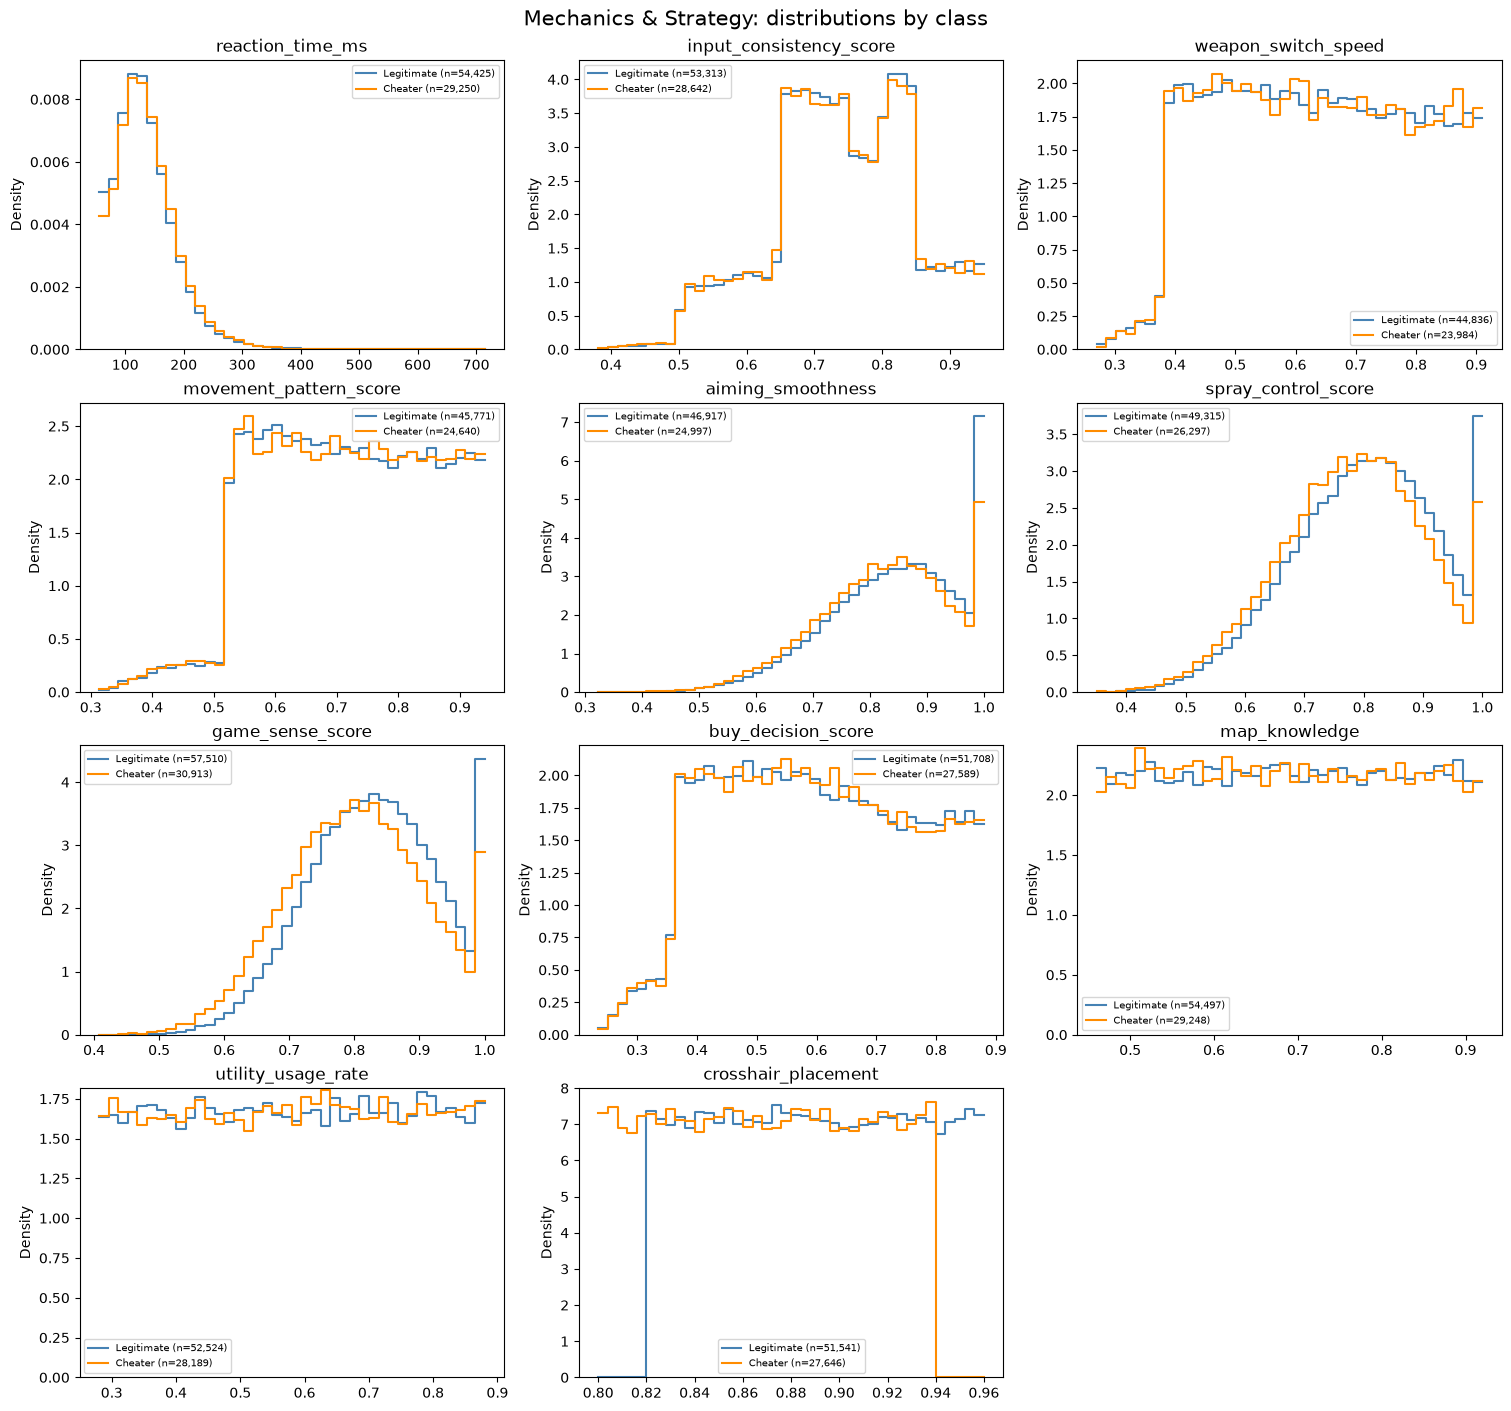

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

mechanics_labeled = train_raw.loc[train_raw[TARGET].isin(LABEL_NAMES)]
fig, axes = plt.subplots(4, 3, figsize=(15, 14), layout="constrained")
for ax, column in zip(axes.flat, mechanics_cols):
    bins = np.histogram_bin_edges(mechanics_labeled[column].dropna(), bins=40)
    for label, color in [(0, "steelblue"), (1, "darkorange")]:
        values = mechanics_labeled.loc[mechanics_labeled[TARGET].eq(label), column].dropna()
        sns.histplot(values, bins=bins, stat="density", element="step", fill=False,
                     color=color, label=f"{LABEL_NAMES[label]} (n={len(values):,})", ax=ax)
    ax.set(title=column, xlabel="", ylabel="Density")
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=7)
for ax in axes.flat[len(mechanics_cols):]:
    ax.set_visible(False)
fig.suptitle("Mechanics & Strategy: distributions by class", fontsize=15)
plt.show()

##### 4.1.2.2 Boxplot ของ Cheater และ Legitimate

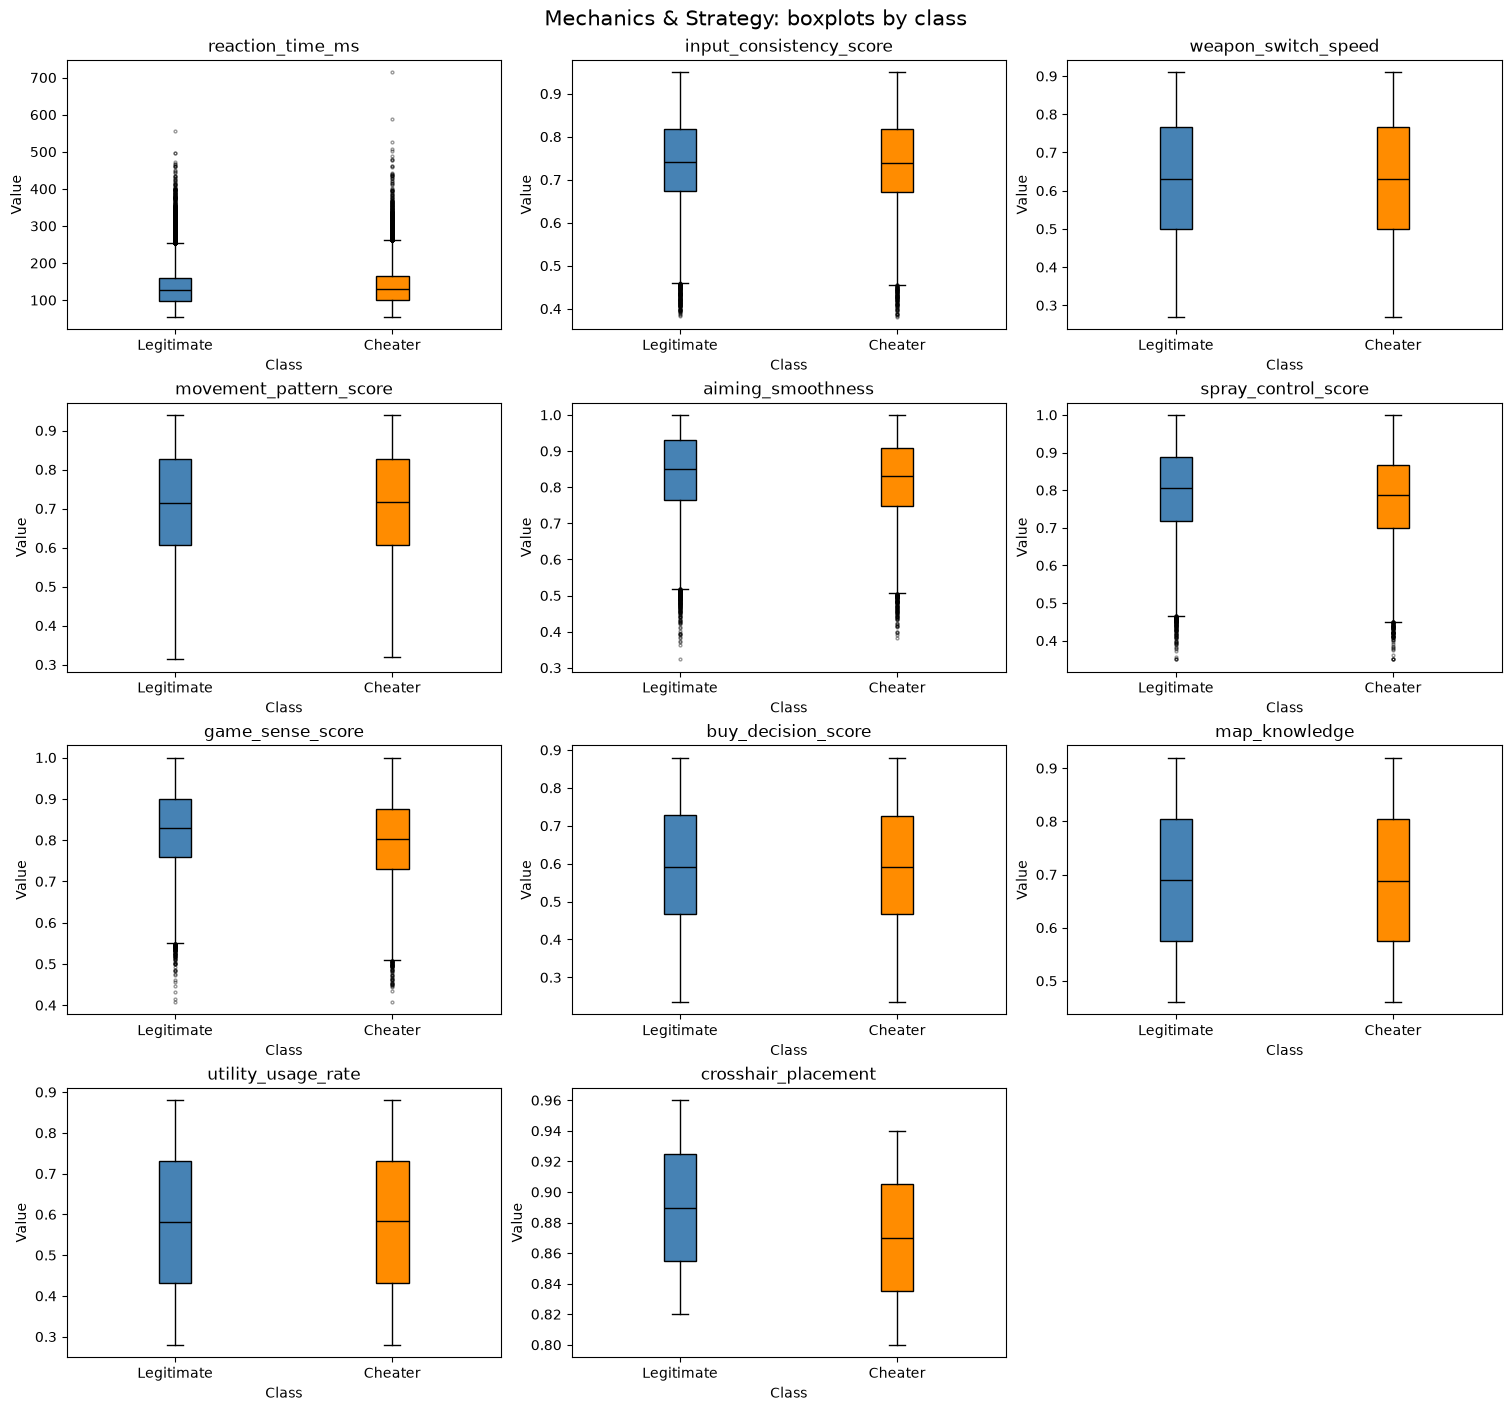

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14), layout="constrained")
for ax, column in zip(axes.flat, mechanics_cols):
    values = [mechanics_labeled.loc[mechanics_labeled[TARGET].eq(label), column].dropna()
              for label in [0, 1]]
    boxes = ax.boxplot(values, tick_labels=[LABEL_NAMES[0], LABEL_NAMES[1]],
                       patch_artist=True, medianprops={"color": "black"},
                       flierprops={"markersize": 2, "alpha": 0.4})
    for patch, color in zip(boxes["boxes"], ["steelblue", "darkorange"]):
        patch.set_facecolor(color)
    ax.set(title=column, xlabel="Class", ylabel="Value")
for ax in axes.flat[len(mechanics_cols):]:
    ax.set_visible(False)
fig.suptitle("Mechanics & Strategy: boxplots by class", fontsize=15)
plt.show()

##### 4.1.2.3 Missing Rate ของ Cheater และ Legitimate

is_cheater,Legitimate,Cheater
reaction_time_ms,7.896,7.801
input_consistency_score,9.778,9.718
weapon_switch_speed,24.124,24.400
movement_pattern_score,22.542,22.333
aiming_smoothness,20.602,21.207
spray_control_score,16.544,17.110
game_sense_score,2.676,2.559
buy_decision_score,12.494,13.037
map_knowledge,7.774,7.808
utility_usage_rate,11.113,11.146


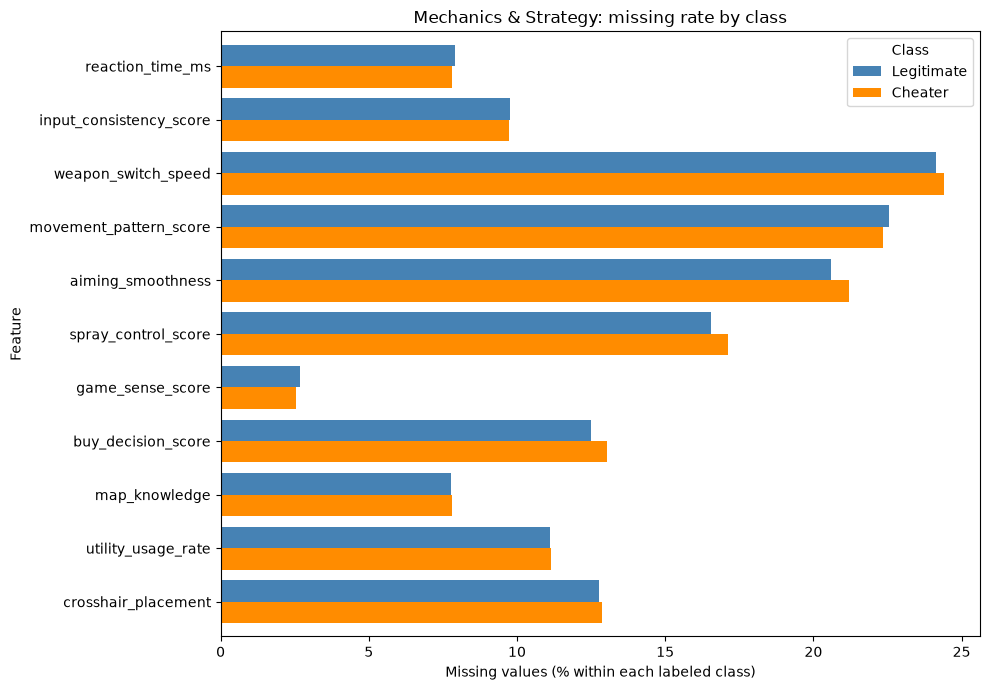

In [ ]:
mechanics_missing_pct = (
    mechanics_labeled[mechanics_cols].isna()
    .groupby(mechanics_labeled[TARGET]).mean().T.mul(100)
    .rename(columns=LABEL_NAMES)
)
display(mechanics_missing_pct.round(3))
ax = mechanics_missing_pct[[LABEL_NAMES[0], LABEL_NAMES[1]]].plot.barh(
    figsize=(10, 7), color=["steelblue", "darkorange"], width=0.8,
)
ax.set(xlabel="Missing values (% within each labeled class)", ylabel="Feature",
       title="Mechanics & Strategy: missing rate by class")
ax.invert_yaxis()
ax.legend(title="Class")
plt.tight_layout()
plt.show()

#### 4.1.3 Account, Social & Activity

In [37]:
account_activity_cols = [
    "account_age_days",
    "level",
    "level_progression_speed",
    "friend_network_size",
    "reports_received",
    "device_changes_count",
    "avg_session_length_min",
    "sessions_per_day",
    "night_play_ratio",
    "communication_rate",
    "team_play_score",
]

In [38]:
stats = train_raw[account_activity_cols].agg(["count", "mean", "median", "min", "max"]).T
stats["count"] = stats["count"].astype(int)
stats["missing_count"] = train_raw[account_activity_cols].isna().sum()
display(stats.round(3))

,count,mean,median,min,max,missing_count
account_age_days,88983,495.254,479.877,1.005,1499.650,15017
level,96586,62.866,62.862,25.006,99.999,7414
level_progression_speed,95560,0.365,0.081,0.003,80.029,8440
friend_network_size,80735,137.767,135.000,0.000,349.000,23265
reports_received,80807,12.912,12.000,4.000,29.000,23193
device_changes_count,100922,7.456,7.000,0.000,15.000,3078
avg_session_length_min,80105,149.917,150.003,25.007,274.997,23895
sessions_per_day,100615,4.946,4.946,0.400,9.500,3385
night_play_ratio,95906,0.379,0.379,0.040,0.720,8094
communication_rate,82598,0.550,0.550,0.220,0.880,21402


##### 4.1.3.1 Distribution ของ Cheater และ Legitimate

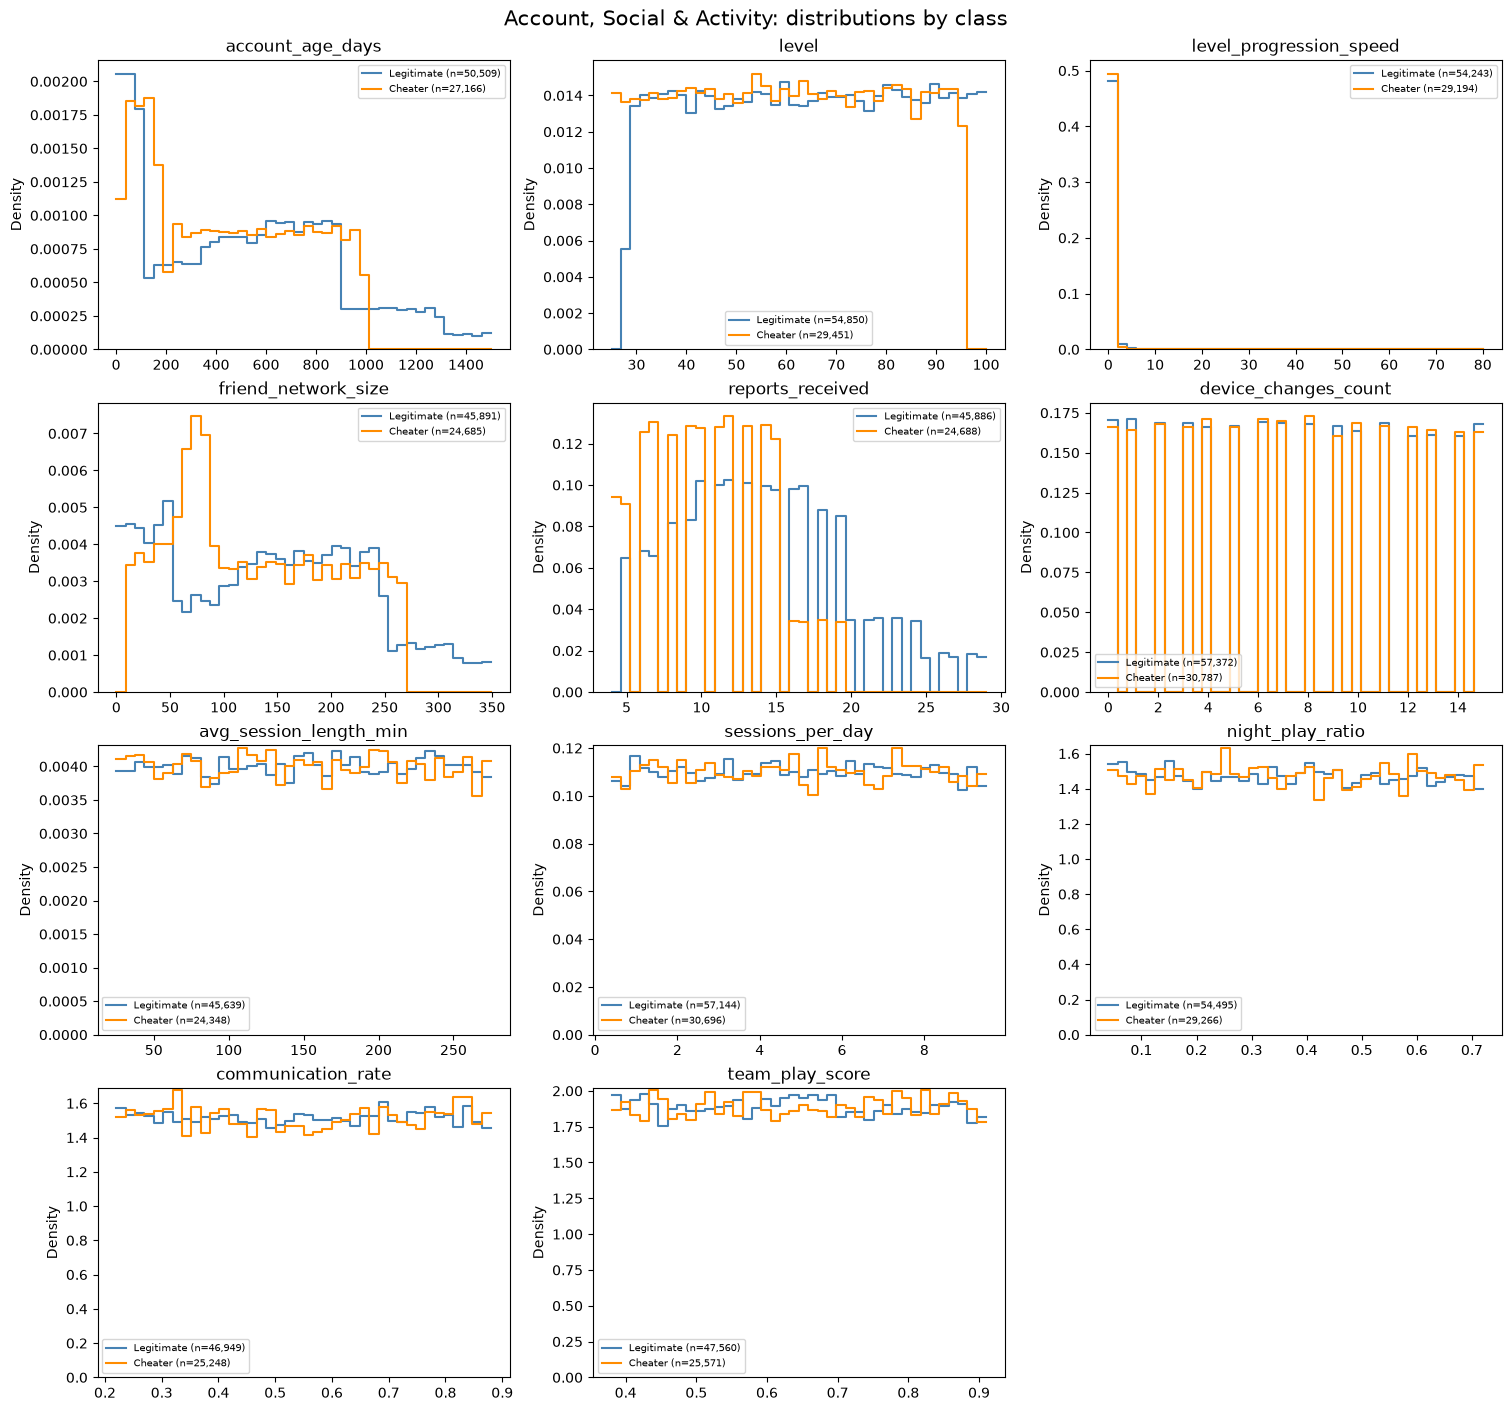

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

account_activity_labeled = train_raw.loc[train_raw[TARGET].isin(LABEL_NAMES)]
fig, axes = plt.subplots(4, 3, figsize=(15, 14), layout="constrained")
for ax, column in zip(axes.flat, account_activity_cols):
    bins = np.histogram_bin_edges(account_activity_labeled[column].dropna(), bins=40)
    for label, color in [(0, "steelblue"), (1, "darkorange")]:
        values = account_activity_labeled.loc[account_activity_labeled[TARGET].eq(label), column].dropna()
        sns.histplot(values, bins=bins, stat="density", element="step", fill=False,
                     color=color, label=f"{LABEL_NAMES[label]} (n={len(values):,})", ax=ax)
    ax.set(title=column, xlabel="", ylabel="Density")
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=7)
for ax in axes.flat[len(account_activity_cols):]:
    ax.set_visible(False)
fig.suptitle("Account, Social & Activity: distributions by class", fontsize=15)
plt.show()

##### 4.1.3.2 Boxplot ของ Cheater และ Legitimate

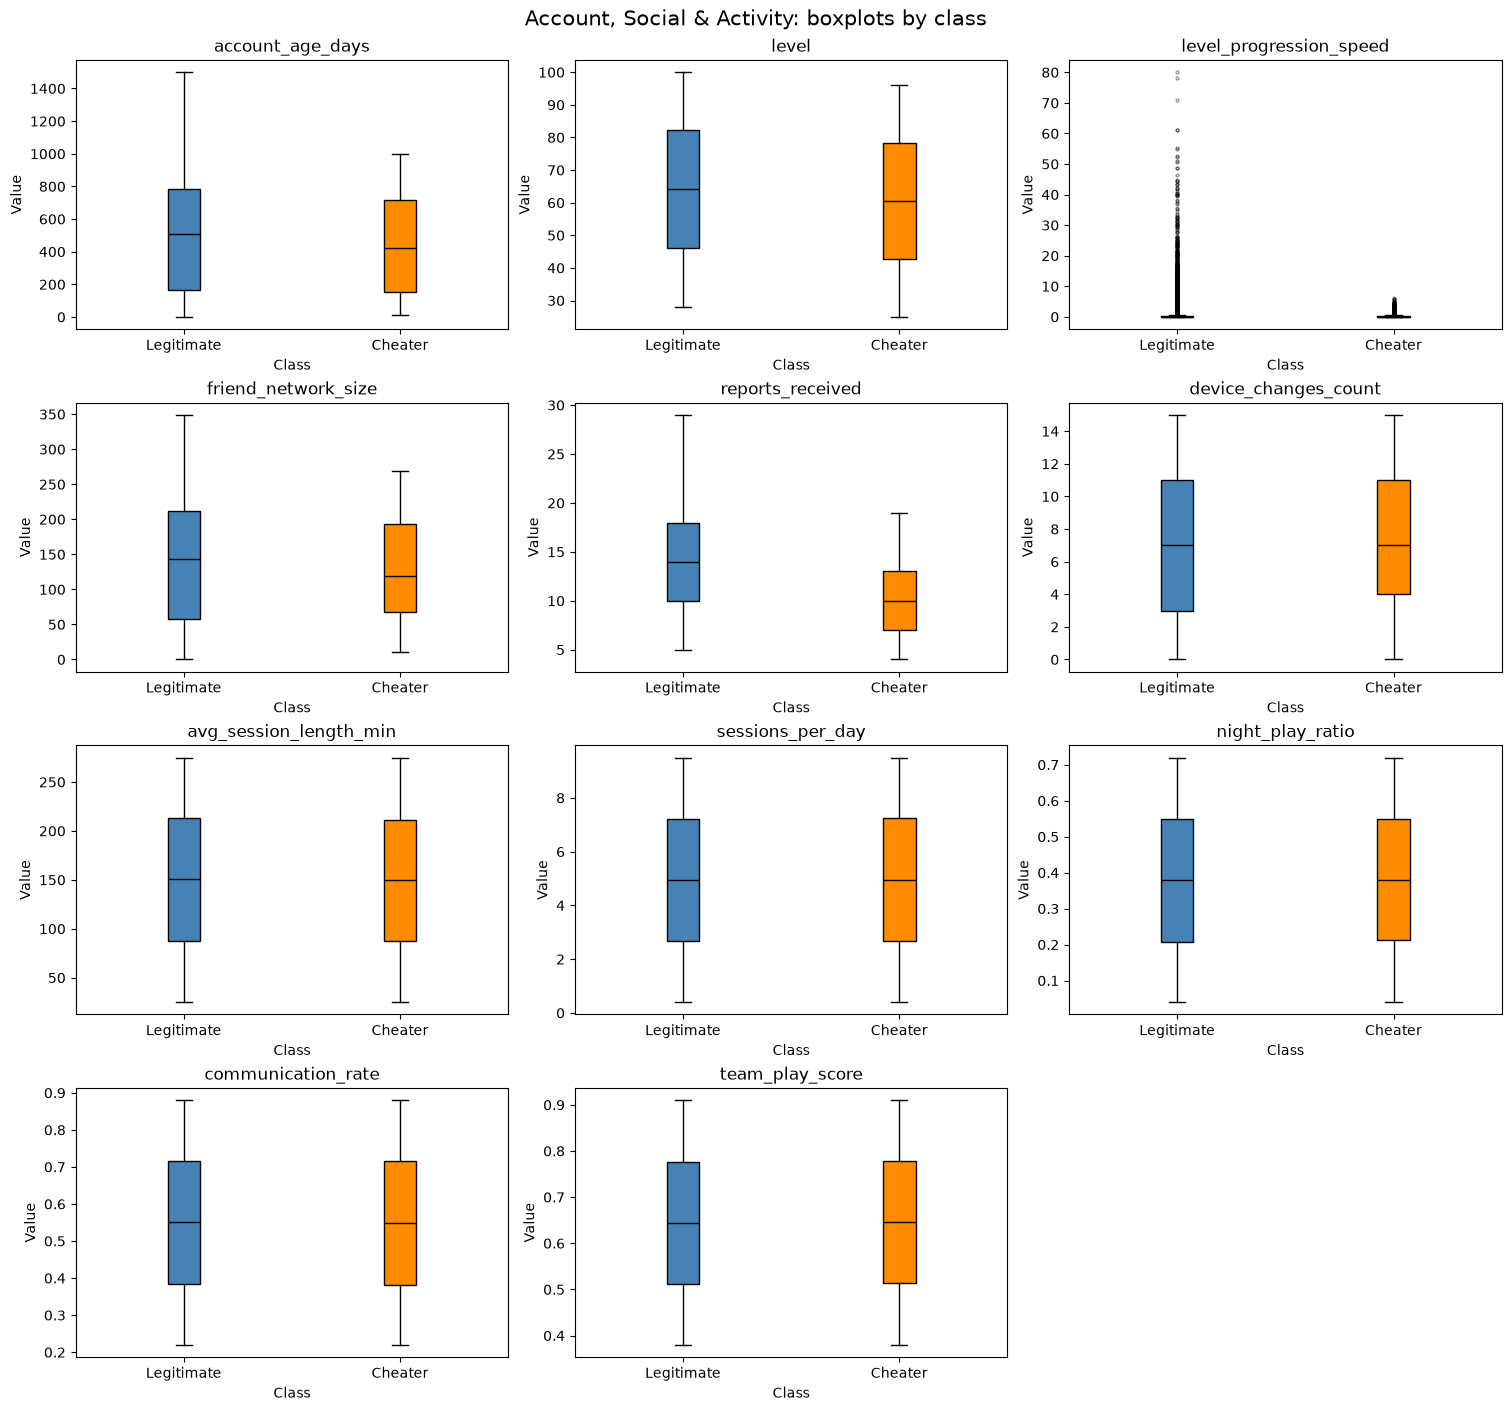

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14), layout="constrained")
for ax, column in zip(axes.flat, account_activity_cols):
    values = [account_activity_labeled.loc[account_activity_labeled[TARGET].eq(label), column].dropna()
              for label in [0, 1]]
    boxes = ax.boxplot(values, tick_labels=[LABEL_NAMES[0], LABEL_NAMES[1]],
                       patch_artist=True, medianprops={"color": "black"},
                       flierprops={"markersize": 2, "alpha": 0.4})
    for patch, color in zip(boxes["boxes"], ["steelblue", "darkorange"]):
        patch.set_facecolor(color)
    ax.set(title=column, xlabel="Class", ylabel="Value")
for ax in axes.flat[len(account_activity_cols):]:
    ax.set_visible(False)
fig.suptitle("Account, Social & Activity: boxplots by class", fontsize=15)
plt.show()

##### 4.1.3.3 Missing Rate ของ Cheater และ Legitimate

is_cheater,Legitimate,Cheater
account_age_days,14.523,14.370
level,7.177,7.168
level_progression_speed,8.204,7.978
friend_network_size,22.338,22.191
reports_received,22.347,22.181
device_changes_count,2.909,2.957
avg_session_length_min,22.765,23.253
sessions_per_day,3.295,3.243
night_play_ratio,7.778,7.751
communication_rate,20.548,20.416


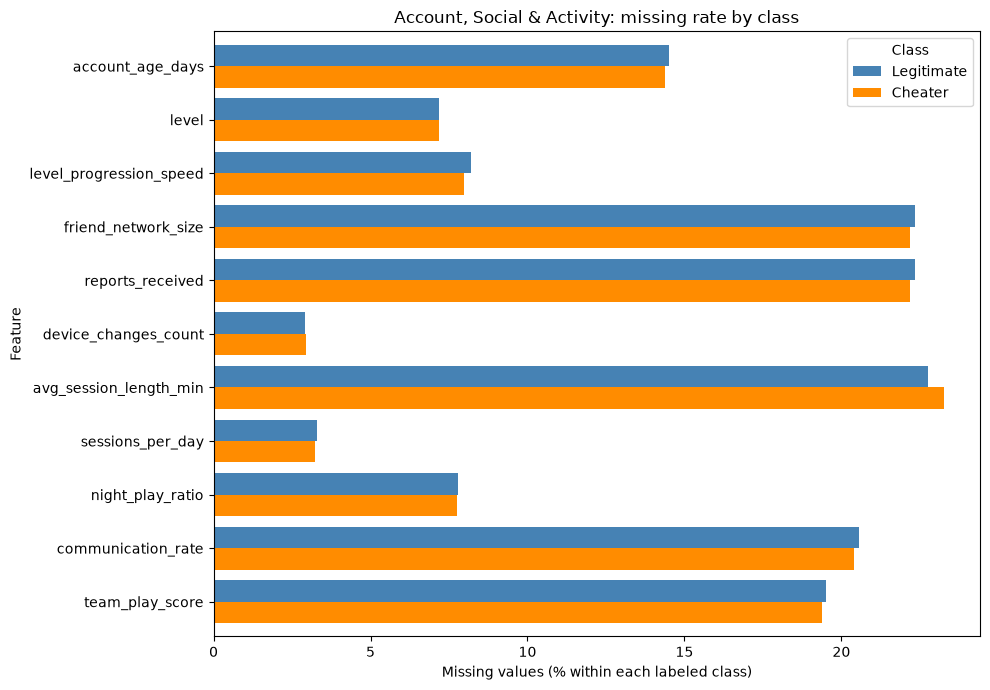

In [ ]:
account_activity_missing_pct = (
    account_activity_labeled[account_activity_cols].isna()
    .groupby(account_activity_labeled[TARGET]).mean().T.mul(100)
    .rename(columns=LABEL_NAMES)
)
display(account_activity_missing_pct.round(3))
ax = account_activity_missing_pct[[LABEL_NAMES[0], LABEL_NAMES[1]]].plot.barh(
    figsize=(10, 7), color=["steelblue", "darkorange"], width=0.8,
)
ax.set(xlabel="Missing values (% within each labeled class)", ylabel="Feature",
       title="Account, Social & Activity: missing rate by class")
ax.invert_yaxis()
ax.legend(title="Class")
plt.tight_layout()
plt.show()

In [ ]:
# ตรวจว่าจัดครบทุก predictor และไม่มีคอลัมน์ซ้ำข้ามหมวด
eda_groups = {
    "performance": performance_cols,
    "mechanics_strategy": mechanics_cols,
    "account_social_activity": account_activity_cols,
}
grouped_cols = [col for columns in eda_groups.values() for col in columns]
require(len(grouped_cols) == len(set(grouped_cols)), "มีคอลัมน์ซ้ำข้ามหมวด EDA")
require(set(grouped_cols) == set(feature_cols), "หมวด EDA ไม่ครอบคลุม predictors ทั้งหมด")
print({name: len(columns) for name, columns in eda_groups.items()}) 

{'performance': 9, 'mechanics_strategy': 11, 'account_social_activity': 11}


### 4.2 Multivariate

#### 4.2.1 Correlation Matrix ของ Train

In [ ]:
corr_matrix = train_raw.corr(method="pearson", numeric_only=True)

Matplotlib is building the font cache; this may take a moment.


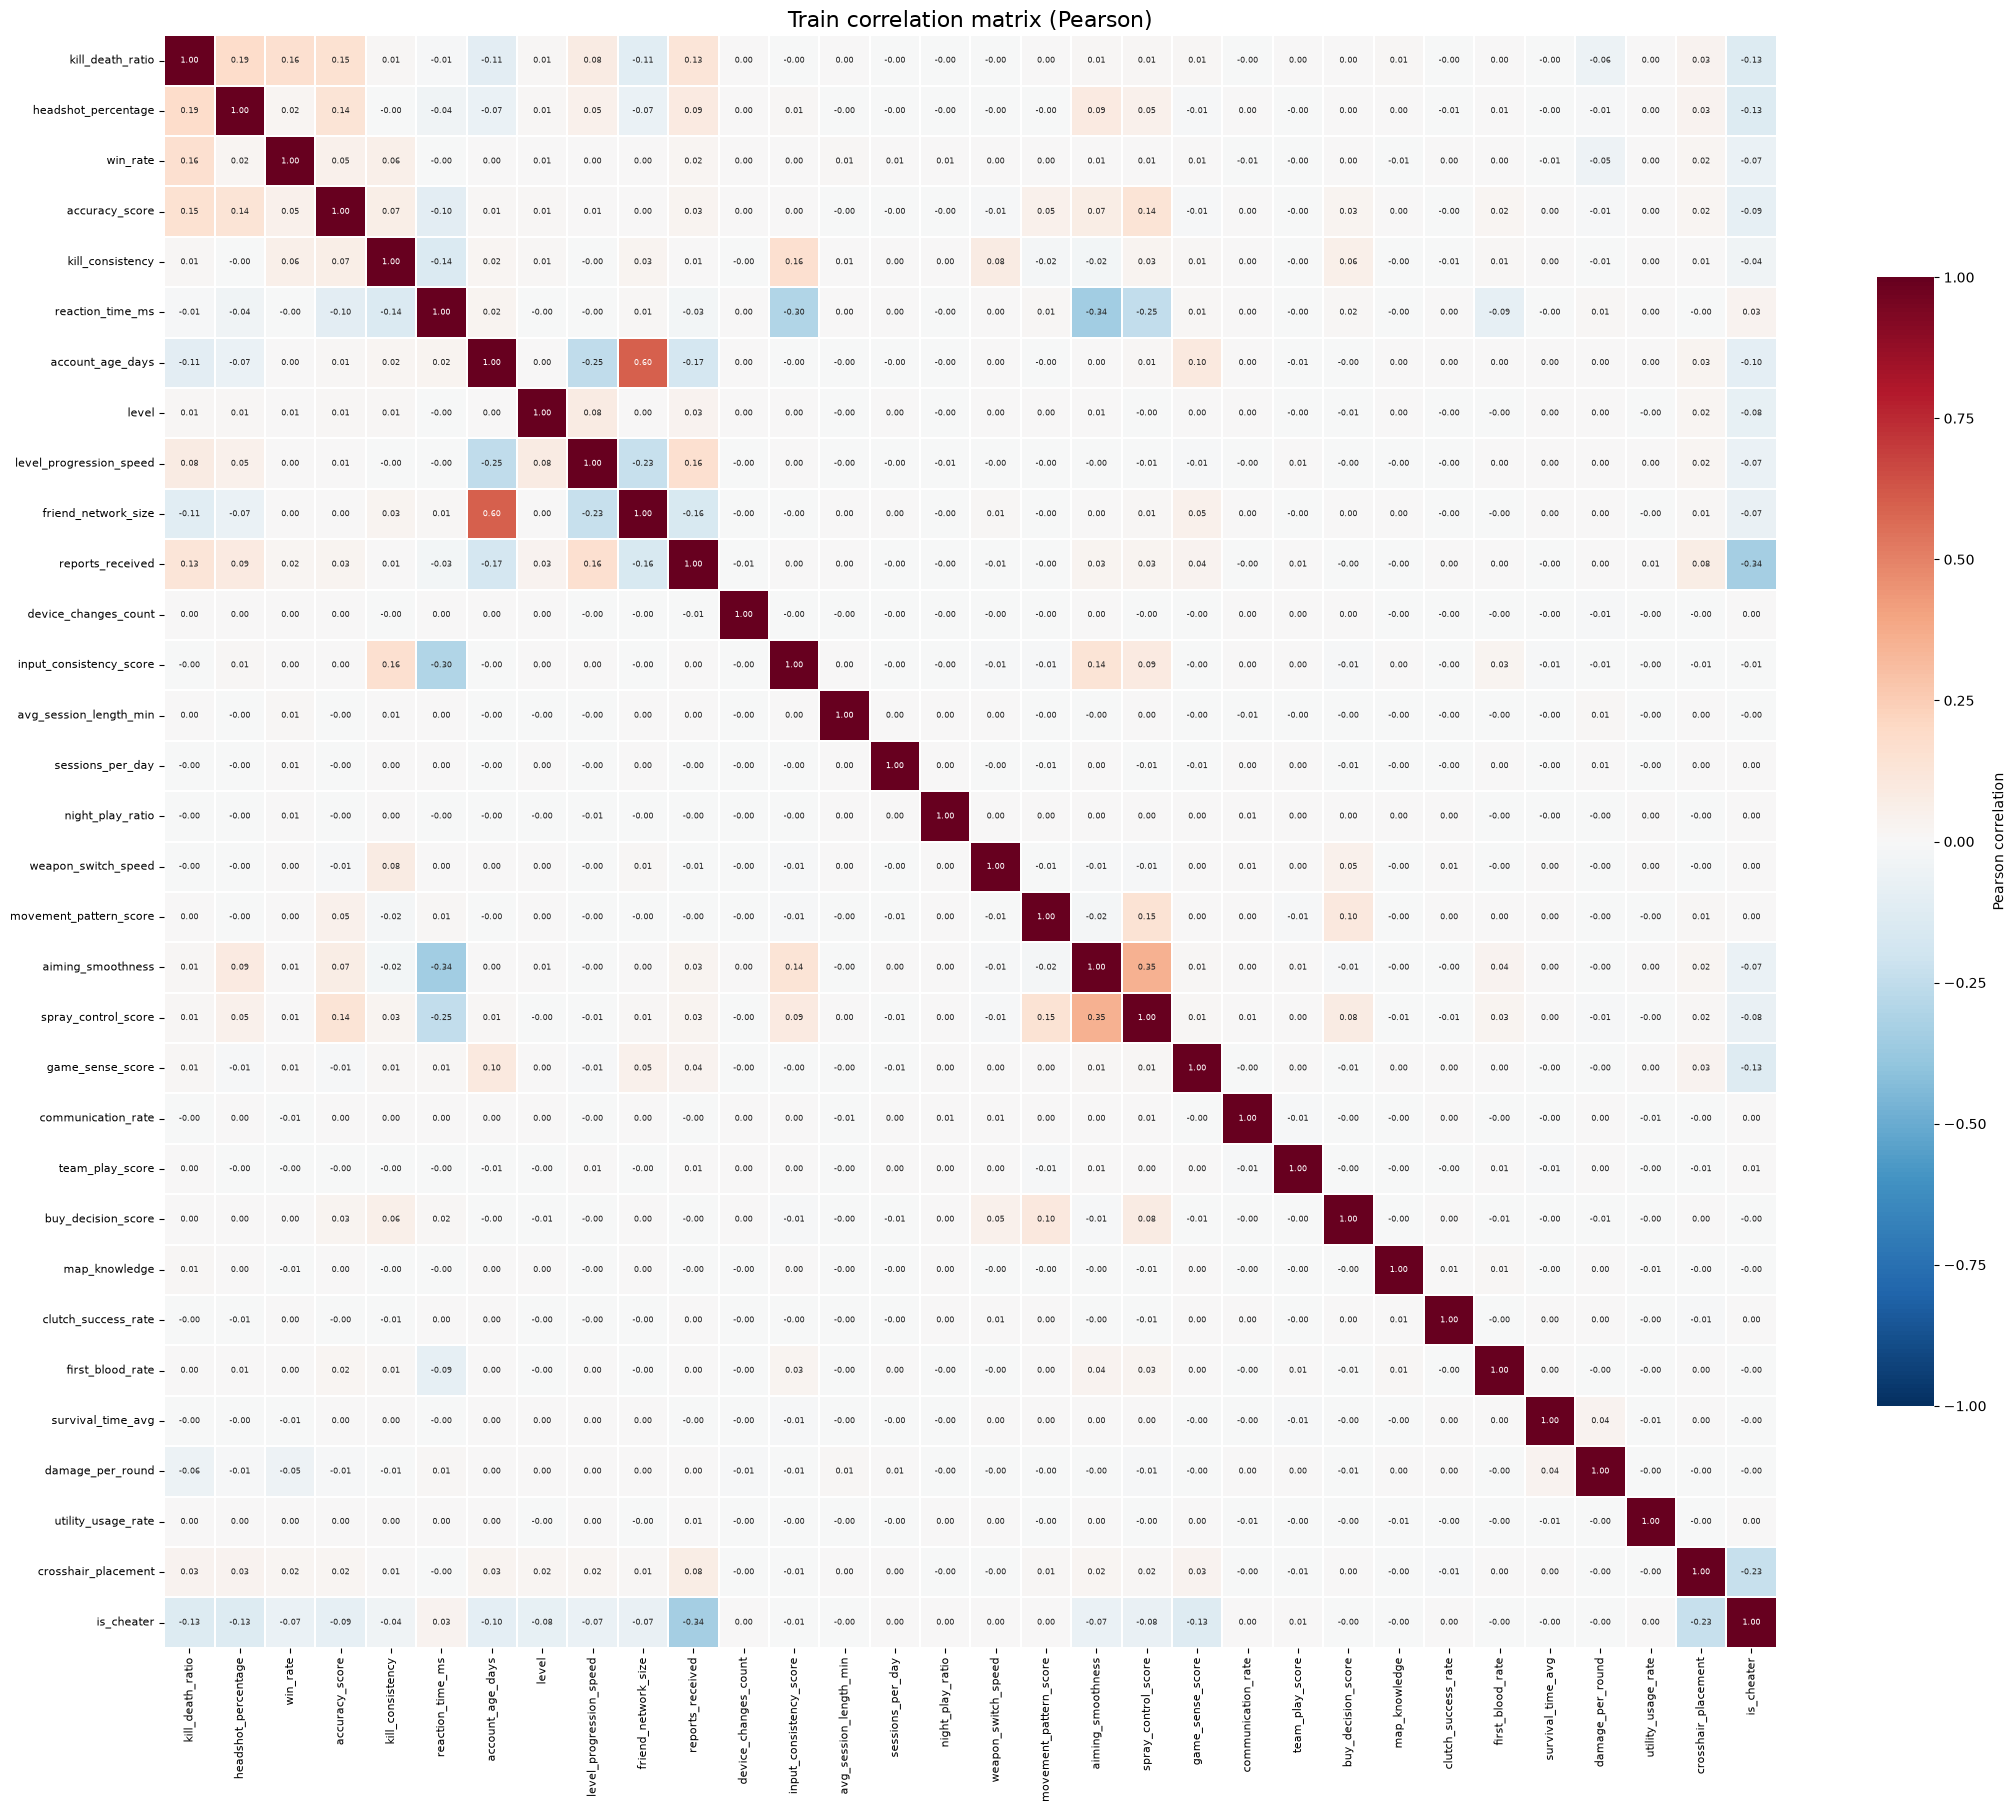

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(22, 18))
sns.heatmap(corr_matrix, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 6}, square=True,
            linewidths=0.2, cbar_kws={"label": "Pearson correlation", "shrink": 0.7}, ax=ax)
ax.set_title("Train correlation matrix (Pearson)", fontsize=16)
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.tick_params(axis="y", labelrotation=0, labelsize=8)
plt.tight_layout()
plt.show()

#### 4.2.2 Account Age Groups

In [ ]:
age_bins = [-np.inf, 90, 365, 730, np.inf]
age_labels = ["<=90 days", ">90–365 days", ">365–730 days", ">730 days"]
age_analysis = train_raw[[ID, "account_age_days", "reports_received", TARGET]].copy()
age_analysis["age_group"] = pd.cut(
    age_analysis["account_age_days"], bins=age_bins, labels=age_labels, right=True,
).cat.add_categories(["Missing"]).fillna("Missing")
assert len(age_analysis) == len(train_raw)
display(age_analysis[["account_age_days", "age_group"]].head())

,account_age_days,age_group
0,261.721035,>90–365 days
1,1075.704820,>730 days
2,1031.540114,>730 days
3,525.534446,>365–730 days
4,296.179584,>90–365 days


In [ ]:
age_summary = age_analysis.groupby("age_group", observed=False)[TARGET].agg(
    total_rows="size", labeled_rows="count",
    legitimate_rows=lambda values: values.eq(0).sum(),
    cheater_rows=lambda values: values.eq(1).sum(),
)
age_summary["missing_target_rows"] = age_summary.total_rows - age_summary.labeled_rows
age_summary["cheater_pct_labeled"] = (
    100 * age_summary.cheater_rows / age_summary.labeled_rows.replace(0, np.nan)
)
assert age_summary.total_rows.sum() == len(train_raw)
display(age_summary.round(3))

,total_rows,labeled_rows,legitimate_rows,cheater_rows,missing_target_rows,cheater_pct_labeled
age_group,,,,,,
<=90 days,14758,12914,9164,3750,1844,29.038
>90–365 days,21064,18381,10045,8336,2683,45.351
>365–730 days,28342,24693,16051,8642,3649,34.998
>730 days,24819,21687,15249,6438,3132,29.686
Missing,15017,13141,8582,4559,1876,34.693


In [ ]:
age_labeled = age_analysis.loc[age_analysis[TARGET].isin(LABEL_NAMES)]
age_reports_by_class = (
    age_labeled.groupby(["age_group", TARGET], observed=False)["reports_received"]
    .agg(total_rows="size", observed_reports="count", mean_reports="mean", median_reports="median")
)
age_reports_by_class["missing_reports"] = (
    age_reports_by_class.total_rows - age_reports_by_class.observed_reports
)
age_reports_by_class = age_reports_by_class.rename(index=LABEL_NAMES, level=TARGET)
display(age_reports_by_class.round(3))

total_rows  observed_reports  mean_reports  \
age_group     is_cheater                                               
<=90 days     Legitimate        9164              7131        19.424   
              Cheater           3750              2934        10.342   
>90–365 days  Legitimate       10045              7755        13.530   
              Cheater           8336              6438        10.491   
>365–730 days Legitimate       16051             12494        12.810   
              Cheater           8642              6776        10.308   
>730 days     Legitimate       15249             11868        13.133   
              Cheater           6438              5032        10.405   
Missing       Legitimate        8582              6638        14.299   
              Cheater           4559              3508        10.445   

                          median_reports  missing_reports  
age_group     is_cheater                                   
<=90 days     Legitimate            19.0             2033  
              Cheater               10.0              816  
>90–365 days  Legitimate            13.0             2290  
              Cheater               10.0             1898  
>365–730 days Legitimate            13.0             3557  
              Cheater               10.0             1866  
>730 days     Legitimate            13.0             3381  
              Cheater               10.0             1406  
Missing       Legitimate            14.0             1944  
              Cheater               10.0             1051

##### 4.2.2.1 Friend Network Size by Account Age

In [ ]:
age_friend_analysis = train_raw[[TARGET, "friend_network_size"]].copy()
age_friend_analysis["age_group"] = age_analysis["age_group"]
age_friend_summary = (
    age_friend_analysis.loc[age_friend_analysis[TARGET].isin(LABEL_NAMES)]
    .groupby(["age_group", TARGET], observed=False)["friend_network_size"]
    .agg(total_rows="size", observed_friends="count", mean_friends="mean", median_friends="median")
)
age_friend_summary["missing_friends"] = age_friend_summary.total_rows - age_friend_summary.observed_friends
age_friend_summary = age_friend_summary.rename(index=LABEL_NAMES, level=TARGET)
display(age_friend_summary.round(3))

total_rows  observed_friends  mean_friends  \
age_group     is_cheater                                               
<=90 days     Legitimate        9164              7040        24.495   
              Cheater           3750              2893        49.107   
>90–365 days  Legitimate       10045              7753       124.332   
              Cheater           8336              6503       103.196   
>365–730 days Legitimate       16051             12471       169.083   
              Cheater           8642              6729       164.504   
>730 days     Legitimate       15249             11881       195.006   
              Cheater           6438              5059       164.888   
Missing       Legitimate        8582              6746       142.683   
              Cheater           4559              3501       127.109   

                          median_friends  missing_friends  
age_group     is_cheater                                   
<=90 days     Legitimate            25.0             2124  
              Cheater               49.0              857  
>90–365 days  Legitimate           123.0             2292  
              Cheater               78.0             1833  
>365–730 days Legitimate           167.0             3580  
              Cheater              165.0             1913  
>730 days     Legitimate           194.0             3368  
              Cheater              166.0             1379  
Missing       Legitimate           142.0             1836  
              Cheater              115.0             1058

Matplotlib is building the font cache; this may take a moment.


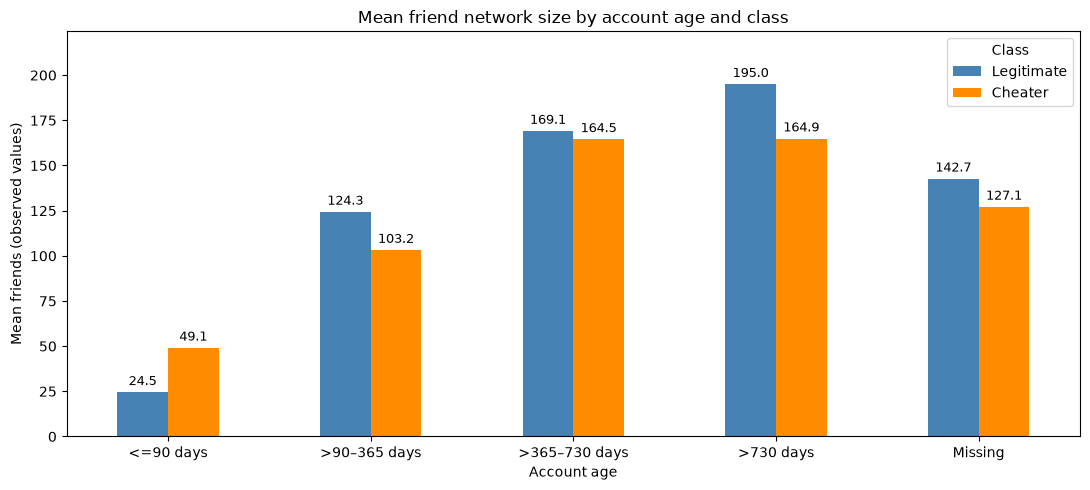

In [ ]:
import matplotlib.pyplot as plt

friend_means = age_friend_summary["mean_friends"].unstack(TARGET)
ax = friend_means[[LABEL_NAMES[0], LABEL_NAMES[1]]].plot.bar(
    figsize=(11, 5), color=["steelblue", "darkorange"], rot=0,
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3, fontsize=9)
ax.set(xlabel="Account age", ylabel="Mean friends (observed values)",
       title="Mean friend network size by account age and class")
ax.set_ylim(0, friend_means.max().max() * 1.15)
ax.legend(title="Class")
plt.tight_layout()
plt.show()

#### 4.2.3 Regression: Account Age vs Friend Network Size

In [ ]:
from scipy.stats import linregress

age_friends_complete = train_raw[["account_age_days", "friend_network_size", TARGET]].dropna(
    subset=["account_age_days", "friend_network_size"]
).copy()
age_friends_groups = {
    "All Train": age_friends_complete,
    "Legitimate": age_friends_complete.loc[age_friends_complete[TARGET].eq(0)],
    "Cheater": age_friends_complete.loc[age_friends_complete[TARGET].eq(1)],
}

In [ ]:
age_friends_regression_rows = []
for name, frame in age_friends_groups.items():
    fit = linregress(frame["account_age_days"], frame["friend_network_size"])
    age_friends_regression_rows.append({
        "group": name, "complete_rows": len(frame), "pearson_r": fit.rvalue,
        "linear_R2": fit.rvalue ** 2, "slope_friends_per_day": fit.slope,
        "intercept": fit.intercept,
    })
age_friends_regression = pd.DataFrame(age_friends_regression_rows).set_index("group")
display(age_friends_regression.round(5))

,complete_rows,pearson_r,linear_R2,slope_friends_per_day,intercept
group,,,,,
All Train,69029,0.59838,0.35805,0.14416,66.24873
Legitimate,39145,0.61614,0.37963,0.14775,65.00291
Cheater,21184,0.54442,0.29639,0.13392,69.87188


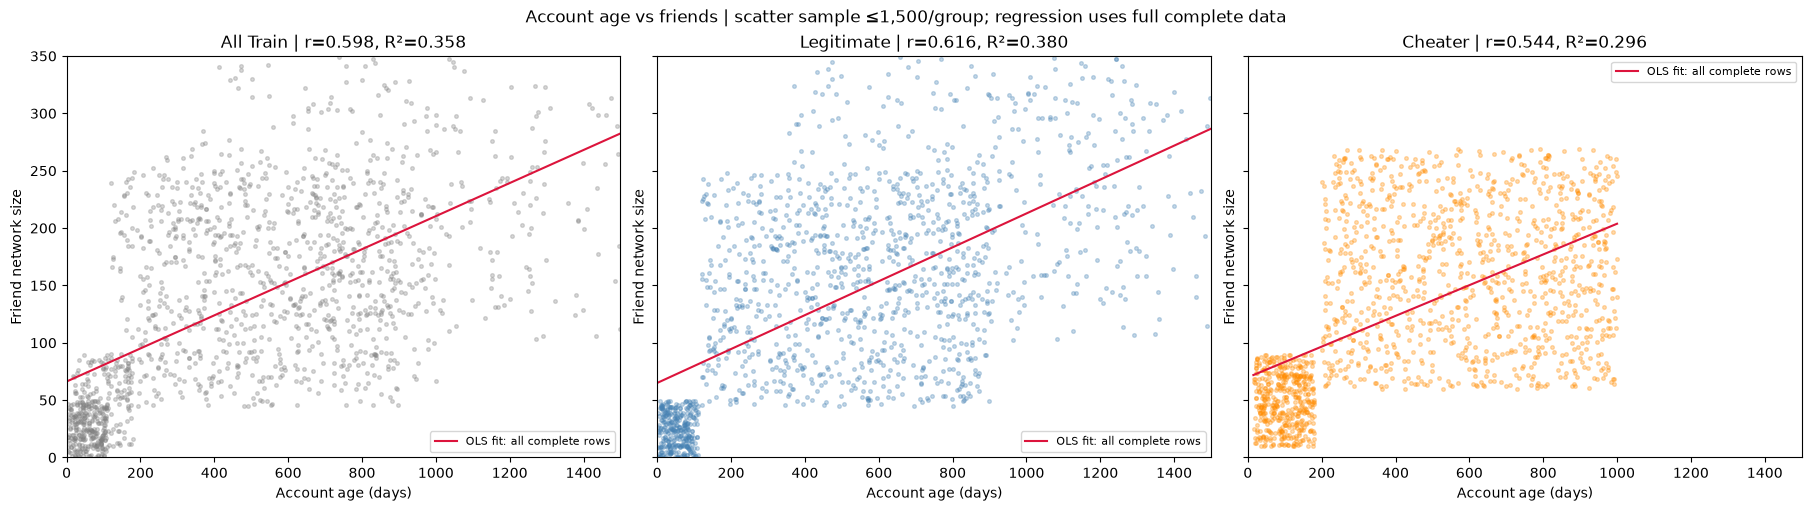

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True, layout="constrained")
for ax, (name, frame), color in zip(axes, age_friends_groups.items(), ["gray", "steelblue", "darkorange"]):
    points = frame.sample(n=min(1_500, len(frame)), random_state=SEED)
    ax.scatter(points.account_age_days, points.friend_network_size, color=color, s=7, alpha=0.3)
    fit = age_friends_regression.loc[name]
    x = np.array([frame.account_age_days.min(), frame.account_age_days.max()])
    ax.plot(x, fit.intercept + fit.slope_friends_per_day * x, color="crimson", label="OLS fit: all complete rows")
    ax.set(title=f"{name} | r={fit.pearson_r:.3f}, R²={fit.linear_R2:.3f}",
           xlabel="Account age (days)", ylabel="Friend network size", xlim=(0, 1_500), ylim=(0, 350))
    ax.legend(fontsize=8)
fig.suptitle("Account age vs friends | scatter sample ≤1,500/group; regression uses full complete data", fontsize=12)
plt.show()

### 4.3 Optional: Feature Combinations and Joint Permutation Importance

การสำรวจนี้สร้างกราฟ 4,960 ภาพหรือประเมิน permutation ของ 4,991 ชุด features ใช้เฉพาะ Train เปิดตัวเลือกในแต่ละส่วนเมื่อต้องการทำซ้ำ ส่วนฝึกและ export ใช้ Run All ได้โดยปิดทั้งสองตัวเลือก

#### 4.3.1 Feature Combinations Export

In [ ]:
RUN_COMBINATION_PLOTS = False

if RUN_COMBINATION_PLOTS:
    from itertools import combinations
    from pathlib import Path
    import hashlib
    import json
    import tempfile
    import time
    from joblib import Parallel, delayed, parallel_config

    COMBO_SAMPLE_PER_CLASS = 1_000
    COMBO_WORKERS = 4
    COMBO_DPI = 100
    COMBO_DIR = OUTPUT_DIR / "temp_feature_combinations_v1"

In [ ]:
if RUN_COMBINATION_PLOTS:
    combo_features = [c for c in train_raw.columns if c not in {ID, TARGET}]
    feature_combinations = [cols for size in (2, 3) for cols in combinations(combo_features, size)]
    combo_catalog = pd.DataFrame({
        "combo_id": range(1, len(feature_combinations) + 1),
        "n_features": [len(cols) for cols in feature_combinations],
        "features": [" | ".join(cols) for cols in feature_combinations],
    })
    assert len(combo_features) == 31 and len(feature_combinations) == 4_960
    display(combo_catalog.groupby("n_features").size().rename("combinations").to_frame())

In [ ]:
if RUN_COMBINATION_PLOTS:
    combo_train = train_raw.loc[train_raw[TARGET].isin(LABEL_NAMES)].copy()
    combo_sample = pd.concat([
        group.sample(n=min(COMBO_SAMPLE_PER_CLASS, len(group)), random_state=SEED)
        for _, group in combo_train.groupby(TARGET)
    ]).sample(frac=1, random_state=SEED)
    combo_sample_X = combo_sample[combo_features].to_numpy(dtype=float)
    combo_sample_y = combo_sample[TARGET].to_numpy(dtype=np.int8)
    combo_full_valid = combo_train[combo_features].notna().to_numpy()
    combo_full_y = combo_train[TARGET].to_numpy(dtype=np.int8)
    combo_feature_index = {name: i for i, name in enumerate(combo_features)}
    print("Labeled Train rows:", len(combo_train), "| Fixed sample rows:", len(combo_sample))

In [ ]:
if RUN_COMBINATION_PLOTS:
    def combo_bits(mask):
        return int.from_bytes(np.packbits(mask, bitorder="little").tobytes(), "little")

    combo_valid_bits = [combo_bits(combo_full_valid[:, i]) for i in range(len(combo_features))]
    combo_class_bits = {label: combo_bits(combo_full_y == label) for label in (0, 1)}
    combo_index_rows = []
    for combo_id, columns in enumerate(feature_combinations, 1):
        indices = [combo_feature_index[name] for name in columns]
        complete_bits = combo_valid_bits[indices[0]]
        for index in indices[1:]:
            complete_bits &= combo_valid_bits[index]
        folder = "pairs" if len(columns) == 2 else "triples"
        filename = f"{combo_id:04d}__" + "__".join(columns) + ".png"
        sampled_valid = np.isfinite(combo_sample_X[:, indices]).all(axis=1)
        row = {"combo_id": combo_id, "n_features": len(columns),
               "feature_x": columns[0], "feature_y": columns[1],
               "feature_z": columns[2] if len(columns) == 3 else "",
               "relative_path": f"{folder}/{filename}"}
        for label, name in [(0, "legitimate"), (1, "cheater")]:
            row[f"full_complete_{name}"] = (complete_bits & combo_class_bits[label]).bit_count()
            row[f"plotted_{name}"] = int((sampled_valid & (combo_sample_y == label)).sum())
        combo_index_rows.append(row)
    combo_index = pd.DataFrame(combo_index_rows)
    display(combo_index.head())

In [ ]:
if RUN_COMBINATION_PLOTS:
    def export_combo_plot(record, sample_X, sample_y, names, output_dir, dpi):
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
        from matplotlib.lines import Line2D
        import os

        path = Path(output_dir) / record["relative_path"]
        if path.is_file() and path.stat().st_size > 0:
            return record["combo_id"]
        columns = [record["feature_x"], record["feature_y"]]
        if record["n_features"] == 3:
            columns.append(record["feature_z"])
        indices = [names.index(name) for name in columns]
        values = sample_X[:, indices]
        valid = np.isfinite(values).all(axis=1)
        values, labels = values[valid], sample_y[valid]
        colors = np.where(labels == 0, "steelblue", "darkorange")
        fig = plt.figure(figsize=(7.5, 6))
        try:
            if len(columns) == 2:
                ax = fig.add_subplot(111)
                ax.scatter(values[:, 0], values[:, 1], c=colors, s=6, alpha=0.4, linewidths=0)
            else:
                ax = fig.add_subplot(111, projection="3d")
                ax.scatter(values[:, 0], values[:, 1], values[:, 2], c=colors,
                           s=5, alpha=0.4, linewidths=0, depthshade=False)
                ax.set_zlabel(columns[2], fontsize=8, labelpad=8)
            ax.set_xlabel(columns[0], fontsize=8)
            ax.set_ylabel(columns[1], fontsize=8)
            handles = [Line2D([], [], marker="o", linestyle="", color=color,
                             label=f"{name} (n={int((labels == label).sum()):,})")
                       for label, name, color in [(0, "Legitimate", "steelblue"),
                                                   (1, "Cheater", "darkorange")]]
            ax.legend(handles=handles, fontsize=8, loc="best")
            ax.set_title(f"Combination {record['combo_id']:04d} | sampled labeled Train", fontsize=11)
            fig.text(0.5, 0.01, "Fixed random sample: up to 1,000/class; missing selected features excluded",
                     ha="center", fontsize=7)
            fig.tight_layout(rect=(0, 0.03, 1, 1))
            path.parent.mkdir(parents=True, exist_ok=True)
            temporary_path = path.with_name(path.stem + ".partial.png")
            fig.savefig(temporary_path, dpi=dpi, bbox_inches="tight")
            os.replace(temporary_path, path)
        finally:
            plt.close(fig)
        return record["combo_id"]

In [ ]:
if RUN_COMBINATION_PLOTS:
    with (RAW_DIR / "train.csv").open("rb") as combo_source:
        combo_source_hash = hashlib.file_digest(combo_source, "sha256").hexdigest()
    combo_settings = {"version": 1, "train_sha256": combo_source_hash, "seed": SEED,
                      "features": combo_features, "sizes": [2, 3],
                      "sample_per_class": COMBO_SAMPLE_PER_CLASS, "dpi": COMBO_DPI}
    COMBO_DIR.mkdir(parents=True, exist_ok=True)
    combo_settings_path = COMBO_DIR / "settings.json"
    if combo_settings_path.exists():
        if json.loads(combo_settings_path.read_text()) != combo_settings:
            raise ValueError("Export settings changed: use a new COMBO_DIR")
    else:
        combo_settings_path.write_text(json.dumps(combo_settings, indent=2) + "\n")
    combo_index.to_csv(COMBO_DIR / "index.csv", index=False)
    print("Output:", COMBO_DIR, "| Planned images:", len(combo_index))

In [ ]:
if RUN_COMBINATION_PLOTS:
    combo_completed = 0
    combo_started = time.monotonic()
    with tempfile.TemporaryDirectory(prefix="cpe342-combo-cache-") as combo_cache:
        with parallel_config(backend="loky", inner_max_num_threads=1):
            results = Parallel(n_jobs=COMBO_WORKERS, return_as="generator_unordered",
                               batch_size=4, max_nbytes="100K", temp_folder=combo_cache)(
                delayed(export_combo_plot)(record, combo_sample_X, combo_sample_y,
                                           combo_features, str(COMBO_DIR), COMBO_DPI)
                for record in combo_index.to_dict("records")
            )
            for combo_id in results:
                combo_completed += 1
                if combo_completed % 100 == 0 or combo_completed == len(combo_index):
                    progress = {"completed": combo_completed, "total": len(combo_index),
                                "elapsed_seconds": round(time.monotonic() - combo_started, 1)}
                    (COMBO_DIR / "progress.json").write_text(json.dumps(progress, indent=2))
                    print(f"Exported {combo_completed:,}/{len(combo_index):,}", flush=True)
    assert all((COMBO_DIR / path).is_file() for path in combo_index.relative_path)
    print("Complete:", COMBO_DIR / "index.csv")

#### 4.3.2 Joint Permutation Importance — LightGBM

In [ ]:
RUN_JOINT_PERMUTATION = False

if RUN_JOINT_PERMUTATION:
    from itertools import combinations
    from pathlib import Path
    import hashlib
    import json
    import time
    import lightgbm as lgb
    from joblib import Parallel, delayed
    from sklearn.model_selection import StratifiedKFold, train_test_split
    from sklearn.metrics import fbeta_score

    JPI_FOLDS, JPI_REPEATS = 3, 3
    JPI_SAMPLE_PER_FOLD, JPI_WORKERS = 2_000, 4
    JPI_THRESHOLD = 0.4
    JPI_DIR = OUTPUT_DIR / "joint_permutation_v1"
    JPI_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31,
                      min_child_samples=30, reg_lambda=1.0, verbosity=-1, n_jobs=4, random_state=SEED)

In [ ]:
if RUN_JOINT_PERMUTATION:
    jpi_train = train_raw.loc[train_raw[TARGET].isin(LABEL_NAMES)].copy()
    jpi_features = [c for c in train_raw if c not in {ID, TARGET}]
    jpi_X = jpi_train[jpi_features].to_numpy(dtype=float)
    jpi_y = jpi_train[TARGET].to_numpy(dtype=np.int8)
    jpi_groups = [indices for size in (1, 2, 3) for indices in combinations(range(len(jpi_features)), size)]
    jpi_splits = list(StratifiedKFold(n_splits=JPI_FOLDS, shuffle=True, random_state=SEED).split(jpi_X, jpi_y))
    assert len(jpi_features) == 31 and len(jpi_groups) == 4_991
    JPI_DIR.mkdir(parents=True, exist_ok=True)
    with (RAW_DIR / "train.csv").open("rb") as source:
        jpi_hash = hashlib.file_digest(source, "sha256").hexdigest()
    jpi_settings = {"version": 1, "train_sha256": jpi_hash, "features": jpi_features,
                    "seed": SEED, "folds": JPI_FOLDS, "repeats": JPI_REPEATS,
                    "sample_per_fold": JPI_SAMPLE_PER_FOLD, "threshold": JPI_THRESHOLD, "params": JPI_PARAMS}
    jpi_settings_path = JPI_DIR / "settings.json"
    if jpi_settings_path.exists():
        if json.loads(jpi_settings_path.read_text()) != jpi_settings:
            raise ValueError("Joint-permutation settings changed: use a new JPI_DIR")
    else:
        jpi_settings_path.write_text(json.dumps(jpi_settings, indent=2) + "\n")
    print("Groups:", {size: sum(len(group) == size for group in jpi_groups) for size in (1, 2, 3)})

In [ ]:
if RUN_JOINT_PERMUTATION:
    def jpi_macro_f2(y_true, prediction):
        tn, fp, fn, tp = np.bincount(2 * y_true + prediction, minlength=4)
        positive_denominator = 5 * tp + 4 * fn + fp
        negative_denominator = 5 * tn + 4 * fp + fn
        positive_f2 = 5 * tp / positive_denominator if positive_denominator else 0.0
        negative_f2 = 5 * tn / negative_denominator if negative_denominator else 0.0
        return float((positive_f2 + negative_f2) / 2)

    for truth, prediction in [([0, 0, 1, 1], [0, 1, 0, 1]), ([0, 1], [0, 0]), ([0, 1], [1, 1])]:
        assert np.isclose(jpi_macro_f2(np.array(truth), np.array(prediction)),
                          fbeta_score(truth, prediction, beta=2, average="macro", labels=[0, 1], zero_division=0))

In [ ]:
if RUN_JOINT_PERMUTATION:
    def jpi_group_scores(group_id, columns, booster, sample_X, sample_y, permutations, baseline, fold):
        shuffled_X = sample_X.copy()
        scores = []
        # The same row permutation is applied to every column in the group.
        for repeat, order in enumerate(permutations, 1):
            shuffled_X[:, columns] = sample_X[order][:, columns]
            probability = booster.predict(shuffled_X, num_threads=1)
            score = jpi_macro_f2(sample_y, (probability >= JPI_THRESHOLD).astype(np.int8))
            scores.append({"group_id": group_id, "fold": fold, "repeat": repeat,
                           "n_features": len(columns), "baseline_macro_F2": baseline,
                           "permuted_macro_F2": score, "importance": baseline - score})
        return scores

    jpi_fold_baselines = []
    jpi_oof_parts = []
    jpi_all_results = []
    jpi_started = time.monotonic()

In [ ]:
if RUN_JOINT_PERMUTATION:
    for fold, (fit_idx, valid_idx) in enumerate(jpi_splits, 1):
        model_path = JPI_DIR / f"fold{fold}_lightgbm.txt"
        if model_path.exists():
            booster = lgb.Booster(model_file=str(model_path))
        else:
            model = lgb.LGBMClassifier(**JPI_PARAMS).fit(jpi_X[fit_idx], jpi_y[fit_idx])
            booster = model.booster_
            booster.save_model(str(model_path))
        full_probability = booster.predict(jpi_X[valid_idx], num_threads=1)
        full_prediction = (full_probability >= JPI_THRESHOLD).astype(np.int8)
        full_score = jpi_macro_f2(jpi_y[valid_idx], full_prediction)
        assert np.isclose(full_score, fbeta_score(jpi_y[valid_idx], full_prediction,
                                               beta=2, average="macro", labels=[0, 1], zero_division=0))
        if JPI_SAMPLE_PER_FOLD < len(valid_idx):
            sample_idx, _ = train_test_split(valid_idx, train_size=JPI_SAMPLE_PER_FOLD,
                                             stratify=jpi_y[valid_idx], random_state=SEED + fold)
        else:
            sample_idx = valid_idx
        sample_X, sample_y = jpi_X[sample_idx], jpi_y[sample_idx]
        sample_probability = booster.predict(sample_X, num_threads=1)
        sample_baseline = jpi_macro_f2(sample_y, (sample_probability >= JPI_THRESHOLD).astype(np.int8))
        permutations = [np.random.default_rng(SEED + repeat).permutation(len(sample_idx))
                        for repeat in range(JPI_REPEATS)]
        jpi_fold_baselines.append({"fold": fold, "train_rows": len(fit_idx), "validation_rows": len(valid_idx),
                                   "importance_sample_rows": len(sample_idx), "macro_F2_full_validation": full_score,
                                   "macro_F2_importance_sample": sample_baseline})
        jpi_oof_parts.append(pd.DataFrame({"row_index": valid_idx, "raw_index": jpi_train.index.to_numpy()[valid_idx],
                                          ID: jpi_train[ID].to_numpy()[valid_idx], "true": jpi_y[valid_idx],
                                          "prob": full_probability, "pred": full_prediction, "fold": fold}))
        pd.DataFrame({"row_index": sample_idx}).to_csv(JPI_DIR / f"fold{fold}_importance_sample.csv", index=False)
        checkpoint = JPI_DIR / f"fold{fold}_joint_permutation.parquet"
        records = pd.read_parquet(checkpoint).to_dict("records") if checkpoint.exists() else []
        completed_groups = {row["group_id"] for row in records}
        pending = [(group_id, columns) for group_id, columns in enumerate(jpi_groups, 1)
                   if group_id not in completed_groups]
        print(f"Fold {fold}: full validation F2={full_score:.5f}; sample F2={sample_baseline:.5f}; pending={len(pending):,}", flush=True)
        results = Parallel(n_jobs=JPI_WORKERS, prefer="threads", return_as="generator_unordered", batch_size=4)(
            delayed(jpi_group_scores)(group_id, columns, booster, sample_X, sample_y,
                                      permutations, sample_baseline, fold)
            for group_id, columns in pending
        )
        for result in results:
            records.extend(result)
            completed_groups.add(result[0]["group_id"])
            if len(completed_groups) % 100 == 0 or len(completed_groups) == len(jpi_groups):
                temporary = checkpoint.with_suffix(".partial.parquet")
                pd.DataFrame(records).to_parquet(temporary, index=False)
                temporary.replace(checkpoint)
                progress = {"fold": fold, "completed_groups": len(completed_groups), "total_groups": len(jpi_groups),
                            "elapsed_seconds": round(time.monotonic() - jpi_started, 1)}
                (JPI_DIR / "progress.json").write_text(json.dumps(progress, indent=2))
                print(f"Fold {fold}: {len(completed_groups):,}/{len(jpi_groups):,}", flush=True)
        assert len(records) == len(jpi_groups) * JPI_REPEATS
        jpi_all_results.extend(records)
    print("All folds complete")

In [ ]:
if RUN_JOINT_PERMUTATION:
    jpi_details = pd.DataFrame(jpi_all_results)
    jpi_ranking = jpi_details.groupby(["group_id", "n_features"], as_index=False).agg(
        importance_mean=("importance", "mean"), importance_std=("importance", "std"),
        permuted_macro_F2_mean=("permuted_macro_F2", "mean"), evaluations=("importance", "size"),
    )
    jpi_ranking["features"] = jpi_ranking.group_id.map(
        {group_id: " | ".join(jpi_features[i] for i in columns) for group_id, columns in enumerate(jpi_groups, 1)}
    )
    jpi_ranking = jpi_ranking.sort_values(["n_features", "importance_mean"], ascending=[True, False])
    jpi_details.to_parquet(JPI_DIR / "all_evaluations.parquet", index=False)
    jpi_ranking.to_csv(JPI_DIR / "ranking_all.csv", index=False)
    for size, name in [(1, "singles"), (2, "pairs"), (3, "triples")]:
        jpi_ranking.loc[jpi_ranking.n_features.eq(size)].to_csv(JPI_DIR / f"ranking_{name}.csv", index=False)
    jpi_baselines = pd.DataFrame(jpi_fold_baselines)
    jpi_baselines.to_csv(JPI_DIR / "fold_baselines.csv", index=False)
    jpi_oof = pd.concat(jpi_oof_parts, ignore_index=True).sort_values("row_index")
    assert jpi_oof.row_index.is_unique and len(jpi_oof) == len(jpi_train)
    jpi_oof.to_parquet(JPI_DIR / "oof_predictions.parquet", index=False)
    display(jpi_baselines.round(5))

In [ ]:
if RUN_JOINT_PERMUTATION:
    for size, name in [(1, "Single features"), (2, "Pairs"), (3, "Triples")]:
        print(name)
        display(jpi_ranking.loc[jpi_ranking.n_features.eq(size),
                                ["features", "importance_mean", "importance_std", "evaluations"]].head(15).round(5))

In [ ]:
if RUN_JOINT_PERMUTATION:
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 2, figsize=(20, 11), layout="constrained")
    for ax, size, title in zip(axes, [2, 3], ["Pairs", "Triples"]):
        top = jpi_ranking.loc[jpi_ranking.n_features.eq(size)].head(10).iloc[::-1]
        labels = top.features.str.replace(" | ", "\n", regex=False)
        ax.barh(labels, top.importance_mean, color="steelblue")
        ax.set(title=title, xlabel="Mean macro F2 drop (3 OOF folds × 3 permutations)")
        ax.tick_params(axis="y", labelsize=8)
        ax.axvline(0, color="gray", linewidth=0.8)
    fig.suptitle("LightGBM joint permutation importance | 31 raw features | fixed threshold 0.4", fontsize=14)
    fig.savefig(JPI_DIR / "top_pairs_triples.png", dpi=120, bbox_inches="tight")
    plt.show()

## 5. Preprocessing & Feature Engineering

### 5.1 Labeled Train

In [78]:
train_labeled = train_raw.loc[train_raw[TARGET].notna()].copy()
train_labeled[TARGET] = train_labeled[TARGET].astype("int8")
model_ids = train_labeled[ID].reset_index(drop=True)
model_raw_indices = train_labeled.index.to_numpy()
y_model = train_labeled[TARGET].reset_index(drop=True)
raw_feature_cols = [c for c in train_raw if c not in {ID, TARGET}]
X_raw_model = train_labeled[raw_feature_cols].reset_index(drop=True)
assert len(raw_feature_cols) == 31 and model_ids.is_unique
assert set(y_model.unique()) == {0, 1}
display(pd.Series({"raw_rows": len(train_raw), "labeled_rows": len(train_labeled),
                   "excluded_missing_target": int(train_raw[TARGET].isna().sum())}, name="rows").to_frame())

,rows
raw_rows,104000
labeled_rows,90816
excluded_missing_target,13184


### 5.2 Row-wise Features

In [79]:
def add_task1_features(frame):
    out = frame.copy()
    out["missing_feature_count"] = frame[raw_feature_cols].isna().sum(axis=1)
    for column in ["account_age_days", "reports_received", "avg_session_length_min", "aiming_smoothness"]:
        out[f"{column}_missing"] = out[column].isna().astype("int8")
    out["reports_per_100_days"] = 100 * out.reports_received / (out.account_age_days + 1)
    out["daily_play_hours"] = out.sessions_per_day * out.avg_session_length_min / 60
    out["headshot_accuracy_gap"] = out.headshot_percentage - out.accuracy_score
    aim = ["aiming_smoothness", "spray_control_score", "crosshair_placement", "input_consistency_score"]
    strategy = ["game_sense_score", "map_knowledge", "team_play_score"]
    out["aim_precision_mean"] = out[aim].mean(axis=1)
    out["aim_precision_spread"] = out[aim].max(axis=1) - out[aim].min(axis=1)
    out["aim_precision_observed"] = out[aim].notna().sum(axis=1)
    out["reaction_adjusted_aim"] = 100 * out.aiming_smoothness / (out.reaction_time_ms + 1)
    out["aim_strategy_gap"] = out[aim].mean(axis=1) - out[strategy].mean(axis=1)
    out["kd_per_teamplay"] = out.kill_death_ratio / (out.team_play_score + 0.1)
    return out

### 5.2.1 Core Pair/Triple Features

In [80]:
from itertools import combinations

CORE_JOINT_COLS = ["account_age_days", "friend_network_size", "reports_received", "crosshair_placement"]
CORE_JOINT_GROUPS = [cols for size in (2, 3) for cols in combinations(CORE_JOINT_COLS, size)]
PRODUCT_FEATURES = ["product__" + "__".join(cols) for cols in CORE_JOINT_GROUPS]
JOINT_CATEGORY_FEATURES = ["joint_bin__" + "__".join(cols) for cols in CORE_JOINT_GROUPS]
JOINT_BINS = {
    "account_age_days": [-np.inf, 90, 365, 730, np.inf],
    "friend_network_size": [-np.inf, 50, 100, 150, 200, 250, np.inf],
    "reports_received": [-np.inf, 5, 10, 15, 20, np.inf],
    "crosshair_placement": [-np.inf, .82, .84, .86, .88, .90, .92, .94, np.inf],
}

def add_task1_joint_features(frame):
    out = frame.copy()
    bins = {column: pd.cut(out[column], edges, right=False, labels=False)
            .astype("Int64").astype("string").fillna("Missing")
            for column, edges in JOINT_BINS.items()}
    for columns, product_name, category_name in zip(CORE_JOINT_GROUPS, PRODUCT_FEATURES, JOINT_CATEGORY_FEATURES):
        product = out[columns[0]].copy()
        category = bins[columns[0]].copy()
        for column in columns[1:]:
            product = product * out[column]
            category = category + "|" + bins[column]
        out[product_name] = product
        out[category_name] = category
    return out

### 5.2.2 Weak singles: pair/triple feature engineering

In [81]:
WEAK_JOINT_GROUPS = [
    ("kill_death_ratio", "win_rate"),
    ("headshot_percentage", "spray_control_score"),
    ("kill_death_ratio", "headshot_percentage", "spray_control_score"),
    ("kill_death_ratio", "win_rate", "accuracy_score"),
]
WEAK_PRODUCT_FEATURES = ["weak_product__" + "__".join(cols) for cols in WEAK_JOINT_GROUPS]
WEAK_CATEGORY_FEATURES = ["weak_bin__" + "__".join(cols) for cols in WEAK_JOINT_GROUPS]
WEAK_BINS = {
    "kill_death_ratio": [-np.inf, 2, 4, 6, 8, np.inf],
    "win_rate": [-np.inf, 40, 60, 80, 100, np.inf],
    "headshot_percentage": [-np.inf, 20, 40, 60, 80, np.inf],
    "spray_control_score": [-np.inf, .6, .7, .8, .9, np.inf],
    "accuracy_score": [-np.inf, 20, 40, 60, 80, np.inf],
}

def add_task1_weak_joint_features(frame):
    out = frame.copy()
    bins = {column: pd.cut(out[column], edges, right=False, labels=False)
            .astype("Int64").astype("string").fillna("Missing")
            for column, edges in WEAK_BINS.items()}
    for columns, product_name, category_name in zip(WEAK_JOINT_GROUPS, WEAK_PRODUCT_FEATURES, WEAK_CATEGORY_FEATURES):
        product = out[columns[0]].copy()
        category = bins[columns[0]].copy()
        for column in columns[1:]:
            product = product * out[column]
            category = category + "|" + bins[column]
        out[product_name] = product
        out[category_name] = category
    return out

weak_feature_manifest = pd.DataFrame({
    "features": [" | ".join(cols) for cols in WEAK_JOINT_GROUPS],
    "product": WEAK_PRODUCT_FEATURES, "joint_bin": WEAK_CATEGORY_FEATURES,
})
display(weak_feature_manifest)


,features,product,joint_bin
0,kill_death_ratio | win_rate,weak_product__kill_death_ratio__win_rate,weak_bin__kill_death_ratio__win_rate
1,headshot_percentage | spray_control_score,weak_product__headshot_percentage__spray_contr...,weak_bin__headshot_percentage__spray_control_s...
2,kill_death_ratio | headshot_percentage | spray...,weak_product__kill_death_ratio__headshot_perce...,weak_bin__kill_death_ratio__headshot_percentag...
3,kill_death_ratio | win_rate | accuracy_score,weak_product__kill_death_ratio__win_rate__accu...,weak_bin__kill_death_ratio__win_rate__accuracy...


### 5.3 Feature Sets & Missing Values

In [82]:
X_friend_featured_model = add_task1_features(X_raw_model)
friend45_cols = X_friend_featured_model.columns.tolist()
reference_removed = ["account_age_days_missing", "reports_received_missing", "avg_session_length_min_missing",
                     "aiming_smoothness_missing", "aim_precision_observed", "missing_feature_count", "map_knowledge"]
reference38_cols = [c for c in friend45_cols if c not in reference_removed]
assert len(friend45_cols) == 45 and len(reference38_cols) == 38
X_featured_model = add_task1_weak_joint_features(add_task1_joint_features(X_friend_featured_model))
assert X_featured_model[raw_feature_cols].equals(X_raw_model)
assert not np.isinf(X_featured_model.select_dtypes(include="number").to_numpy()).any()
display(pd.Series({"raw_features": len(raw_feature_cols), "friend_features": len(friend45_cols),
                   "numeric_products": len(PRODUCT_FEATURES), "joint_categories": len(JOINT_CATEGORY_FEATURES)}).to_frame("count"))
assert len(WEAK_PRODUCT_FEATURES) == len(WEAK_CATEGORY_FEATURES) == 4
assert len(X_featured_model.columns) == 73
display(X_featured_model[WEAK_PRODUCT_FEATURES + WEAK_CATEGORY_FEATURES].head())

,count
raw_features,31
friend_features,45
numeric_products,10
joint_categories,10


,weak_product__kill_death_ratio__win_rate,weak_product__headshot_percentage__spray_control_score,weak_product__kill_death_ratio__headshot_percentage__spray_control_score,weak_product__kill_death_ratio__win_rate__accuracy_score,weak_bin__kill_death_ratio__win_rate,weak_bin__headshot_percentage__spray_control_score,weak_bin__kill_death_ratio__headshot_percentage__spray_control_score,weak_bin__kill_death_ratio__win_rate__accuracy_score
0,443.411648,NaN,NaN,11288.305187,2|3,2|Missing,2|2|Missing,2|3|1
1,645.662663,43.633258,284.068298,23682.631407,3|3,2|3,3|2|3,3|3|1
2,545.716709,41.967975,229.026251,24316.430984,2|4,3|1,2|3|1,2|4|2
3,NaN,31.305677,NaN,NaN,Missing|3,1|3,Missing|1|3,Missing|3|2
4,353.498515,26.988695,108.223639,10040.042395,2|3,2|1,2|2|1,2|3|1


### 5.4 Candidate Models

In [83]:
BASE_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31,
                   min_child_samples=30, max_depth=-1, reg_lambda=1.0,
                   verbosity=-1, n_jobs=4, random_state=SEED)
DROP2_FEATURES = ["utility_usage_rate", "sessions_per_day"]
DROP7_FEATURES = DROP2_FEATURES + ["first_blood_rate", "avg_session_length_min", "clutch_success_rate",
                                   "input_consistency_score", "reaction_time_ms"]
kept_drop2 = [c for c in raw_feature_cols if c not in DROP2_FEATURES]
kept_drop7 = [c for c in raw_feature_cols if c not in DROP7_FEATURES]
FEATURE_SETS = {
    "raw24": kept_drop7,
    "raw31": raw_feature_cols,
    "raw24_weak_products": kept_drop7 + WEAK_PRODUCT_FEATURES,
}

# Each configuration is fixed before looking at this round's OOF results.
# 500/800 trees isolate tree count; the other candidates test explicit hypotheses.
CANDIDATE_PLAN = [
    ("simple_drop7", "raw24", {}, "Previous best baseline"),
    ("trees500", "raw24", {"n_estimators": 500}, "More boosting rounds, same learning rate"),
    ("trees800", "raw24", {"n_estimators": 800}, "More boosting rounds, same learning rate"),
    ("slow800", "raw24", {"n_estimators": 800, "learning_rate": .02}, "Smaller updates over more rounds"),
    ("shallow_regularized", "raw24", {"n_estimators": 800, "learning_rate": .02,
        "num_leaves": 15, "max_depth": 5, "min_child_samples": 100, "reg_lambda": 5.0},
        "Reduce noisy splits and model variance"),
    ("deep_regularized", "raw24", {"n_estimators": 800, "learning_rate": .02,
        "num_leaves": 63, "max_depth": 8, "min_child_samples": 100, "reg_lambda": 5.0},
        "Allow finer interactions with stronger regularization"),
    ("slow800_bagging", "raw24", {"n_estimators": 800, "learning_rate": .02,
        "subsample": .8, "subsample_freq": 1, "colsample_bytree": .9},
        "Row and column sampling to reduce reliance on particular observations/features"),
    ("slow800_raw31", "raw31", {"n_estimators": 800, "learning_rate": .02},
        "Check whether previously dropped features help with a different fit"),
    ("slow800_weak_products", "raw24_weak_products", {"n_estimators": 800, "learning_rate": .02},
        "Recheck the four weak-single products under smaller updates"),
]
model_specs = {
    name: dict(features=FEATURE_SETS[feature_set].copy(), missing="native",
               params={**BASE_PARAMS, **overrides})
    for name, feature_set, overrides, hypothesis in CANDIDATE_PLAN
}
candidate_plan = pd.DataFrame([
    {"model": name, "feature_set": feature_set, "n_features": len(model_specs[name]["features"]),
     **model_specs[name]["params"], "hypothesis": hypothesis}
    for name, feature_set, overrides, hypothesis in CANDIDATE_PLAN
])
feature_set_manifest = pd.DataFrame([
    {"feature_set": name, "position": i, "feature": feature}
    for name, columns in FEATURE_SETS.items() for i, feature in enumerate(columns)
])
for columns in FEATURE_SETS.values():
    assert len(columns) == len(set(columns))
    assert set(columns) <= set(X_featured_model.columns)
    assert TARGET not in columns and ID not in columns
assert [len(cols) for cols in FEATURE_SETS.values()] == [24, 31, 28]
display(candidate_plan)
display(feature_set_manifest.groupby("feature_set")["feature"].apply(list).to_frame())


,model,feature_set,n_features,n_estimators,learning_rate,num_leaves,min_child_samples,max_depth,reg_lambda,verbosity,n_jobs,random_state,hypothesis,subsample,subsample_freq,colsample_bytree
0,simple_drop7,raw24,24,300,0.05,31,30,-1,1.0,-1,4,42,Previous best baseline,NaN,NaN,NaN
1,trees500,raw24,24,500,0.05,31,30,-1,1.0,-1,4,42,"More boosting rounds, same learning rate",NaN,NaN,NaN
2,trees800,raw24,24,800,0.05,31,30,-1,1.0,-1,4,42,"More boosting rounds, same learning rate",NaN,NaN,NaN
3,slow800,raw24,24,800,0.02,31,30,-1,1.0,-1,4,42,Smaller updates over more rounds,NaN,NaN,NaN
4,shallow_regularized,raw24,24,800,0.02,15,100,5,5.0,-1,4,42,Reduce noisy splits and model variance,NaN,NaN,NaN
5,deep_regularized,raw24,24,800,0.02,63,100,8,5.0,-1,4,42,Allow finer interactions with stronger regular...,NaN,NaN,NaN
6,slow800_bagging,raw24,24,800,0.02,31,30,-1,1.0,-1,4,42,Row and column sampling to reduce reliance on ...,0.8,1.0,0.9
7,slow800_raw31,raw31,31,800,0.02,31,30,-1,1.0,-1,4,42,Check whether previously dropped features help...,NaN,NaN,NaN
8,slow800_weak_products,raw24_weak_products,28,800,0.02,31,30,-1,1.0,-1,4,42,Recheck the four weak-single products under sm...,NaN,NaN,NaN


,feature
feature_set,
raw24,"[kill_death_ratio, headshot_percentage, win_ra..."
raw24_weak_products,"[kill_death_ratio, headshot_percentage, win_ra..."
raw31,"[kill_death_ratio, headshot_percentage, win_ra..."


## 6. Cross-Validation & OOF Strategy

### 6.1 Repeated OOF Splits

In [84]:
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, TunedThresholdClassifierCV
from sklearn.metrics import fbeta_score, make_scorer, confusion_matrix, precision_score, recall_score

outer_cv6 = RepeatedStratifiedKFold(n_splits=3, n_repeats=2, random_state=SEED)
outer_splits6 = list(outer_cv6.split(X_raw_model, y_model))
threshold_grid = np.linspace(0.10, 0.90, 33)
macro_f2_scorer = make_scorer(fbeta_score, beta=2, average="macro", zero_division=0)
fold_assignments = pd.concat([
    pd.DataFrame({"row_index": valid_idx, "raw_index": model_raw_indices[valid_idx],
                  ID: model_ids.iloc[valid_idx].to_numpy(), "fold": fold,
                  "repeat": (fold - 1) // 3 + 1, "split": (fold - 1) % 3 + 1})
    for fold, (_, valid_idx) in enumerate(outer_splits6, 1)
], ignore_index=True)
assert len(outer_splits6) == 6 and len(fold_assignments) == 2 * len(y_model)
assert fold_assignments.groupby(["repeat", "row_index"]).size().eq(1).all()
display(fold_assignments.groupby(["repeat", "fold"]).size().rename("validation_rows").to_frame())

validation_rows
repeat fold                 
1      1               30272
       2               30272
       3               30272
2      4               30272
       5               30272
       6               30272

### 6.2 Artifact Settings & Data Fingerprints

In [ ]:
from pathlib import Path
import hashlib
import json
import time
import joblib
from importlib.metadata import version

ML_RUN_NAME = "single_notebook_cv6_v4"
ML_DIR = OUTPUT_DIR / ML_RUN_NAME
ML_DIR.mkdir(parents=True, exist_ok=True)
with (RAW_DIR / "train.csv").open("rb") as source:
    ml_train_hash = hashlib.file_digest(source, "sha256").hexdigest()
ml_feature_hash = hashlib.sha256(pd.util.hash_pandas_object(X_featured_model, index=True).to_numpy().tobytes()).hexdigest()
ml_settings = {"run": ML_RUN_NAME, "seed": SEED, "outer_folds": 3, "repeats": 2, "inner_folds": 3,
               "thresholds": threshold_grid.tolist(), "train_sha256": ml_train_hash,
               "feature_data_sha256": ml_feature_hash, "candidates": model_specs, "weak_joint_groups": [list(g) for g in WEAK_JOINT_GROUPS],
               "weak_bins": {k: [str(v) for v in edges] for k, edges in WEAK_BINS.items()},
               "versions": {name: version(name) for name in ["numpy", "pandas", "scikit-learn", "lightgbm"]},
               "reference_params_provenance": "Fixed hypothesis-driven hyperparameter candidates; same outer folds and inner threshold protocol; no outer-fold early stopping."}
ml_settings_path = ML_DIR / "settings.json"
if ml_settings_path.exists():
    if json.loads(ml_settings_path.read_text()) != ml_settings:
        raise ValueError("Data/configuration changed: choose a new ML_RUN_NAME")
else:
    if any(ML_DIR.iterdir()):
        raise FileExistsError("Nonempty run directory without settings: use a new ML_RUN_NAME")
    ml_settings_path.write_text(json.dumps(ml_settings, indent=2) + "\n")
weak_feature_manifest.to_csv(ML_DIR / "engineered_feature_manifest.csv", index=False)
fold_assignments.to_parquet(ML_DIR / "fold_assignments.parquet", index=False)
print("Artifacts:", ML_DIR)
candidate_plan.to_csv(ML_DIR / "candidate_plan.csv", index=False)
feature_set_manifest.to_csv(ML_DIR / "feature_set_manifest.csv", index=False)

### 6.3 Reuse Matched Baseline

In [ ]:
import shutil

previous_dir = OUTPUT_DIR / "single_notebook_cv6_v3"
if (previous_dir / "settings.json").exists():
    previous_settings = json.loads((previous_dir / "settings.json").read_text())
    assert previous_settings["train_sha256"] == ml_settings["train_sha256"]
    assert previous_settings["thresholds"] == ml_settings["thresholds"]
    assert previous_settings["versions"] == ml_settings["versions"]
    assert previous_settings["candidates"]["simple_drop7"] == model_specs["simple_drop7"]
    assert pd.read_parquet(previous_dir / "fold_assignments.parquet").equals(fold_assignments)
    for fold in range(1, 7):
        for extension in ["parquet", "json"]:
            source = previous_dir / f"simple_drop7_fold{fold}.{extension}"
            destination = ML_DIR / source.name
            if source.exists() and not destination.exists():
                shutil.copy2(source, destination)
    print("Matching baseline checkpoints reused; missing folds will be trained")
else:
    print("Previous artifacts unavailable: baseline will be trained with all other candidates")

## 7. Model Training & Threshold Selection

### 7.1 Fold-local Preprocessing & Threshold Selection

In [87]:
from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder
from sklearn.feature_selection import SelectFromModel


def make_cv6_model(spec):
    steps = []
    categorical = spec.get("categorical", [])
    if categorical:
        numeric = [c for c in spec["features"] if c not in categorical]
        encoder = TargetEncoder(target_type="binary", smooth="auto", cv=3, shuffle=True, random_state=SEED)
        steps.append(("joint_encoding", ColumnTransformer([
            ("numeric", "passthrough", numeric), ("joint_target", encoder, categorical),
        ], remainder="drop")))
    if spec["missing"] == "median":
        steps.append(("imputer", SimpleImputer(strategy="median", keep_empty_features=True)))
    if spec.get("select") == "median_gain":
        selector = LGBMClassifier(**spec["params"], importance_type="gain")
        steps.append(("feature_selection", SelectFromModel(selector, threshold="median")))
    steps.append(("classifier", LGBMClassifier(**spec["params"])))
    return TunedThresholdClassifierCV(
        estimator=Pipeline(steps), scoring=macro_f2_scorer, thresholds=threshold_grid,
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED), refit=True, n_jobs=1,
    )

### 7.2 Evaluation Helpers

In [88]:
def cv6_metrics(truth, prediction):
    tn, fp, fn, tp = confusion_matrix(truth, prediction, labels=[0, 1]).ravel()
    return {"macro_F2": float(fbeta_score(truth, prediction, beta=2, average="macro", zero_division=0)),
            "F2_legitimate": float(fbeta_score(truth, prediction, beta=2, pos_label=0, zero_division=0)),
            "F2_cheater": float(fbeta_score(truth, prediction, beta=2, pos_label=1, zero_division=0)),
            "precision_cheater": float(precision_score(truth, prediction, zero_division=0)),
            "recall_cheater": float(recall_score(truth, prediction, zero_division=0)),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}


def atomic_cv6_parquet(frame, destination):
    temporary = destination.with_suffix(".partial.parquet")
    frame.to_parquet(temporary, index=False)
    temporary.replace(destination)

### 7.3 OOF Training & Checkpoints

In [89]:
def run_cv6_candidate(name):
    spec = model_specs[name]
    X = X_featured_model[spec["features"]]
    parts, scores = [], []
    for fold, (fit_idx, valid_idx) in enumerate(outer_splits6, 1):
        path = ML_DIR / f"{name}_fold{fold}.parquet"
        repeat, split = (fold - 1) // 3 + 1, (fold - 1) % 3 + 1
        if path.exists():
            part = pd.read_parquet(path)
            print(name, "fold", fold, "loaded", flush=True)
        else:
            started = time.monotonic()
            model = make_cv6_model(spec)
            model.fit(X.iloc[fit_idx], y_model.iloc[fit_idx])
            probability = model.predict_proba(X.iloc[valid_idx])[:, 1]
            prediction = model.predict(X.iloc[valid_idx]).astype("int8")
            part = pd.DataFrame({"model": name, "row_index": valid_idx,
                                 "raw_index": model_raw_indices[valid_idx], ID: model_ids.iloc[valid_idx].to_numpy(),
                                 "true": y_model.iloc[valid_idx].to_numpy(), "prob": probability, "pred": prediction,
                                 "threshold": float(model.best_threshold_), "fold": fold, "repeat": repeat, "split": split})
            atomic_cv6_parquet(part, path)
            timing = {"model": name, "fold": fold, "fit_seconds": round(time.monotonic() - started, 2)}
            (ML_DIR / f"{name}_fold{fold}.json").write_text(json.dumps(timing, indent=2))
        ordered = part.sort_values("row_index")
        expected = np.sort(valid_idx)
        assert part.row_index.is_unique and np.array_equal(ordered.row_index.to_numpy(), expected)
        assert np.array_equal(ordered[ID].to_numpy(), model_ids.iloc[expected].to_numpy())
        assert np.array_equal(ordered["true"].to_numpy(), y_model.iloc[expected].to_numpy())
        assert part.fold.eq(fold).all() and part.repeat.eq(repeat).all()
        assert part["model"].eq(name).all() and part.threshold.nunique() == 1
        assert np.isfinite(part.prob).all() and part.prob.between(0, 1).all()
        metrics = cv6_metrics(part["true"], part.pred)
        scores.append({"model": name, "fold": fold, "repeat": repeat, "split": split,
                       "threshold": float(part.threshold.iloc[0]), **metrics})
        parts.append(part)
        progress = {"model": name, "fold": fold, "folds": 6,
                    "completed_fold_files": len(list(ML_DIR.glob("*_fold*.parquet"))),
                    "total_candidate_folds": len(model_specs) * 6}
        (ML_DIR / "progress.json").write_text(json.dumps(progress, indent=2))
        print(f"{name} fold {fold}/6: macro F2={metrics['macro_F2']:.5f}, threshold={part.threshold.iloc[0]:.3f}", flush=True)
    oof = pd.concat(parts, ignore_index=True).sort_values(["repeat", "row_index"])
    assert len(oof) == len(y_model) * 2
    assert oof.groupby(["repeat", "row_index"]).size().eq(1).all()
    atomic_cv6_parquet(oof, ML_DIR / f"{name}_oof.parquet")
    pd.DataFrame(scores).to_csv(ML_DIR / f"{name}_fold_scores.csv", index=False)
    display(pd.DataFrame(scores)[["fold", "repeat", "threshold", "macro_F2", "F2_legitimate", "F2_cheater"]].round(5))
    return oof, pd.DataFrame(scores)

cv6_results = {}

### 7.4 Run Hyperparameter Comparison

Run sections 1–3 and 5–7.3 first; section 4 is not required for training. This cell trains all 9 candidates with outer 3 folds × 2 repeats and inner 3-fold threshold tuning. With baseline checkpoints, 48 new outer folds require 192 LightGBM fits. Completed folds are cached for resume. Keep settings unchanged when resuming; use a new `ML_RUN_NAME` after editing candidates.

After this finishes, run section 8 to compare results, then section 9 to refit the selected model and predict Test. Scores use previously explored folds and are not an untouched estimate. No score improvement is guaranteed.

In [90]:
cv6_results = {}
for candidate_number, name in enumerate(model_specs, 1):
    print(f"\nCandidate {candidate_number}/{len(model_specs)}: {name}", flush=True)
    cv6_results[name] = run_cv6_candidate(name)
print("Completed: run section 8 to compare OOF scores and paired fold differences")


Candidate 1/9: simple_drop7
simple_drop7 fold 1 loaded
simple_drop7 fold 1/6: macro F2=0.77876, threshold=0.375
simple_drop7 fold 2 loaded
simple_drop7 fold 2/6: macro F2=0.77839, threshold=0.400
simple_drop7 fold 3 loaded
simple_drop7 fold 3/6: macro F2=0.78053, threshold=0.375
simple_drop7 fold 4 loaded
simple_drop7 fold 4/6: macro F2=0.77674, threshold=0.400
simple_drop7 fold 5 loaded
simple_drop7 fold 5/6: macro F2=0.77703, threshold=0.400
simple_drop7 fold 6 loaded
simple_drop7 fold 6/6: macro F2=0.77772, threshold=0.400


,fold,repeat,threshold,macro_F2,F2_legitimate,F2_cheater
0,1,1,0.375,0.77876,0.79566,0.76185
1,2,1,0.400,0.77839,0.82015,0.73664
2,3,1,0.375,0.78053,0.80095,0.76011
3,4,2,0.400,0.77674,0.81758,0.73590
4,5,2,0.400,0.77703,0.82243,0.73163
5,6,2,0.400,0.77772,0.82058,0.73487



Candidate 2/9: trees500
trees500 fold 1/6: macro F2=0.77836, threshold=0.400
trees500 fold 2/6: macro F2=0.77606, threshold=0.400
trees500 fold 3/6: macro F2=0.77973, threshold=0.375
trees500 fold 4/6: macro F2=0.77742, threshold=0.400
trees500 fold 5/6: macro F2=0.77633, threshold=0.375
trees500 fold 6/6: macro F2=0.77825, threshold=0.375


,fold,repeat,threshold,macro_F2,F2_legitimate,F2_cheater
0,1,1,0.400,0.77836,0.82022,0.73651
1,2,1,0.400,0.77606,0.81951,0.73262
2,3,1,0.375,0.77973,0.80087,0.75859
3,4,2,0.400,0.77742,0.81733,0.73750
4,5,2,0.375,0.77633,0.80105,0.75161
5,6,2,0.375,0.77825,0.79800,0.75850



Candidate 3/9: trees800
trees800 fold 1/6: macro F2=0.77552, threshold=0.400
trees800 fold 2/6: macro F2=0.77379, threshold=0.400
trees800 fold 3/6: macro F2=0.77732, threshold=0.375
trees800 fold 4/6: macro F2=0.77316, threshold=0.375
trees800 fold 5/6: macro F2=0.77412, threshold=0.350
trees800 fold 6/6: macro F2=0.77650, threshold=0.375


,fold,repeat,threshold,macro_F2,F2_legitimate,F2_cheater
0,1,1,0.400,0.77552,0.81881,0.73224
1,2,1,0.400,0.77379,0.81833,0.72926
2,3,1,0.375,0.77732,0.80147,0.75317
3,4,2,0.375,0.77316,0.79401,0.75232
4,5,2,0.350,0.77412,0.78007,0.76818
5,6,2,0.375,0.77650,0.79960,0.75340


... (9 outputs left out)

,fold,repeat,threshold,macro_F2,F2_legitimate,F2_cheater
0,1,1,0.400,0.77775,0.82010,0.73540
1,2,1,0.400,0.77691,0.82027,0.73355
2,3,1,0.375,0.77980,0.79990,0.75970
3,4,2,0.375,0.77496,0.79119,0.75873
4,5,2,0.375,0.77858,0.79947,0.75770
5,6,2,0.375,0.77840,0.79552,0.76129



Candidate 9/9: slow800_weak_products
slow800_weak_products fold 1/6: macro F2=0.78015, threshold=0.375
slow800_weak_products fold 2/6: macro F2=0.77738, threshold=0.400
slow800_weak_products fold 3/6: macro F2=0.77894, threshold=0.400
slow800_weak_products fold 4/6: macro F2=0.77666, threshold=0.400
slow800_weak_products fold 5/6: macro F2=0.77927, threshold=0.375
slow800_weak_products fold 6/6: macro F2=0.77884, threshold=0.400


,fold,repeat,threshold,macro_F2,F2_legitimate,F2_cheater
0,1,1,0.375,0.78015,0.79597,0.76433
1,2,1,0.400,0.77738,0.81965,0.73511
2,3,1,0.400,0.77894,0.82156,0.73632
3,4,2,0.400,0.77666,0.81786,0.73545
4,5,2,0.375,0.77927,0.79972,0.75882
5,6,2,0.400,0.77884,0.82169,0.73598


Completed: run section 8 to compare OOF scores and paired fold differences


## 8. OOF Evaluation & Error Analysis

### 8.1 Paired Fold Scores

In [97]:
cv6_scores = pd.concat([result[1] for result in cv6_results.values()], ignore_index=True)
cv6_summary = cv6_scores.groupby("model", as_index=False).agg(
    mean_macro_F2=("macro_F2", "mean"), std_macro_F2=("macro_F2", "std"),
    min_macro_F2=("macro_F2", "min"), mean_F2_legitimate=("F2_legitimate", "mean"),
    mean_F2_cheater=("F2_cheater", "mean"), mean_threshold=("threshold", "mean"),
).sort_values("mean_macro_F2", ascending=False).reset_index(drop=True)
cv6_paired = cv6_scores.pivot(index="fold", columns="model", values="macro_F2")
cv6_scores.to_csv(ML_DIR / "fold_scores.csv", index=False)
cv6_summary.to_csv(ML_DIR / "model_ranking.csv", index=False)
display(cv6_summary.round(6))
display(cv6_paired.round(6))
baseline_scores = cv6_paired["simple_drop7"]
paired_improvement = pd.DataFrame([
    {"model": name, "mean_delta_vs_baseline": (cv6_paired[name] - baseline_scores).mean(),
     "folds_better": int((cv6_paired[name] > baseline_scores).sum()),
     "folds_worse": int((cv6_paired[name] < baseline_scores).sum())}
    for name in cv6_paired.columns
]).sort_values("mean_delta_vs_baseline", ascending=False)
paired_improvement.to_csv(ML_DIR / "paired_baseline_comparison.csv", index=False)
display(paired_improvement.round(6))


,model,mean_macro_F2,std_macro_F2,min_macro_F2,mean_F2_legitimate,mean_F2_cheater,mean_threshold
0,slow800_bagging,0.779107,0.001600,0.776002,0.805547,0.752668,0.383333
1,slow800_weak_products,0.778540,0.001286,0.776659,0.812744,0.744337,0.391667
2,slow800,0.778489,0.001588,0.776295,0.804465,0.752513,0.383333
3,deep_regularized,0.778231,0.001219,0.776349,0.811909,0.744552,0.395833
4,simple_drop7,0.778195,0.001379,0.776738,0.812891,0.743499,0.391667
5,slow800_raw31,0.777734,0.001661,0.774962,0.804408,0.751060,0.383333
6,trees500,0.777692,0.001378,0.776064,0.809497,0.745887,0.387500
7,shallow_regularized,0.777066,0.000509,0.776458,0.811661,0.742471,0.400000
8,trees800,0.775070,0.001641,0.773163,0.802046,0.748094,0.379167


model,deep_regularized,shallow_regularized,simple_drop7,slow800,slow800_bagging,slow800_raw31,slow800_weak_products,trees500,trees800
fold,,,,,,,,,
1,0.779735,0.777026,0.778759,0.779660,0.780204,0.777749,0.780151,0.778361,0.775524
2,0.778034,0.777258,0.778392,0.777083,0.779024,0.776910,0.777379,0.776064,0.773791
3,0.777618,0.777828,0.780528,0.780165,0.779788,0.779797,0.778945,0.779730,0.777317
4,0.776349,0.776552,0.776738,0.776295,0.776002,0.774962,0.776659,0.777415,0.773163
5,0.778315,0.776458,0.777029,0.779687,0.779322,0.778584,0.779269,0.776330,0.774123
6,0.779331,0.777274,0.777723,0.778044,0.780303,0.778403,0.778839,0.778250,0.776501


,model,mean_delta_vs_baseline,folds_better,folds_worse
4,slow800_bagging,0.000912,4,2
6,slow800_weak_products,0.000345,3,3
3,slow800,0.000294,3,3
0,deep_regularized,0.000036,3,3
2,simple_drop7,0.000000,0,0
5,slow800_raw31,-0.000461,2,4
7,trees500,-0.000503,2,4
1,shallow_regularized,-0.001129,0,6
8,trees800,-0.003125,0,6


### 8.2 Comparison with Friend Reference

In [ ]:
friend_reference_path = OUTPUT_DIR / "round3_lgbm_combined_pruned_cv6.json"
if friend_reference_path.exists():
    friend_record = json.loads(friend_reference_path.read_text())
    friend_fold_scores = pd.DataFrame(friend_record["folds"])[["fold", "macro_F2", "threshold"]].rename(
        columns={"macro_F2": "friend_macro_F2", "threshold": "friend_threshold"})
    friend_comparison = cv6_scores.merge(friend_fold_scores, on="fold", validate="many_to_one")
    friend_comparison["delta_vs_friend"] = friend_comparison.macro_F2 - friend_comparison.friend_macro_F2
    friend_comparison.to_csv(ML_DIR / "friend_fold_comparison.csv", index=False)
    friend_comparison_summary = friend_comparison.groupby("model").agg(
        mean_delta=("delta_vs_friend", "mean"), fold_wins=("delta_vs_friend", lambda x: int((x > 0).sum())))
    display(friend_comparison_summary.round(6))
    display(friend_comparison.loc[friend_comparison.model.eq("lgbm_reference38"),
                                  ["fold", "macro_F2", "friend_macro_F2", "delta_vs_friend", "threshold", "friend_threshold"]].round(6))
else:
    print("Friend fold-score file unavailable; our OOF files remain available for comparison")

### 8.3 Fold-score Plot

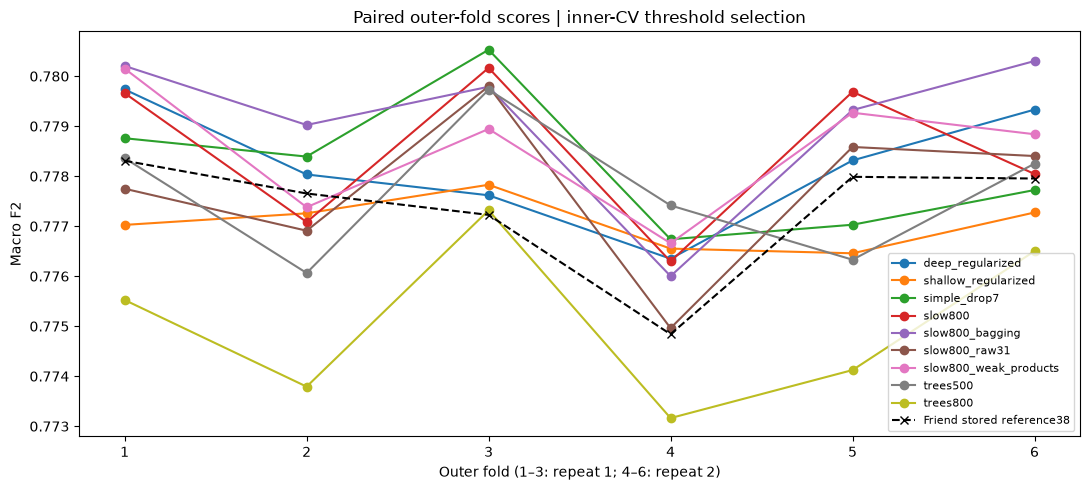

In [99]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 5))
for name, frame in cv6_scores.groupby("model"):
    ax.plot(frame.fold, frame.macro_F2, marker="o", label=name)
if friend_reference_path.exists():
    ax.plot(friend_fold_scores.fold, friend_fold_scores.friend_macro_F2,
            color="black", linestyle="--", marker="x", label="Friend stored reference38")
ax.set(xlabel="Outer fold (1–3: repeat 1; 4–6: repeat 2)", ylabel="Macro F2",
       title="Paired outer-fold scores | inner-CV threshold selection")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 8.4 Selected Model & Repeat Metrics

In [100]:
SELECTED_MODEL_NAME = cv6_summary.iloc[0]["model"]
selected_spec = model_specs[SELECTED_MODEL_NAME]
selected_oof = pd.read_parquet(ML_DIR / f"{SELECTED_MODEL_NAME}_oof.parquet")
for repeat, frame in selected_oof.groupby("repeat"):
    atomic_cv6_parquet(frame, ML_DIR / f"selected_oof_repeat{repeat}.parquet")
repeat_metrics = pd.DataFrame([
    {"repeat": repeat, **cv6_metrics(frame["true"], frame.pred)}
    for repeat, frame in selected_oof.groupby("repeat")
])
repeat_metrics.to_csv(ML_DIR / "selected_repeat_metrics.csv", index=False)
print("Selected:", SELECTED_MODEL_NAME, "| Mean of 6 outer-fold macro F2:", cv6_summary.iloc[0].mean_macro_F2)
display(repeat_metrics.round(6))

Selected: slow800_bagging | Mean of 6 outer-fold macro F2: 0.7791072361890197


,repeat,macro_F2,F2_legitimate,F2_cheater,precision_cheater,recall_cheater,TN,FP,FN,TP
0,1,0.779675,0.798429,0.760921,0.660239,0.791080,46176,12915,6628,25097
1,2,0.778631,0.812743,0.744519,0.673440,0.764697,47327,11764,7465,24260


### 8.5 Confusion Matrices by Repeat

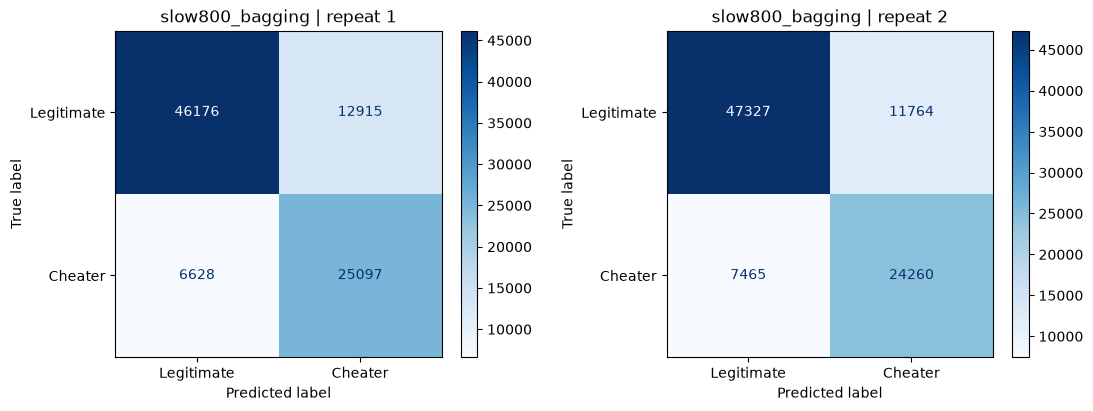

In [101]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, (repeat, frame) in zip(axes, selected_oof.groupby("repeat")):
    ConfusionMatrixDisplay.from_predictions(frame["true"], frame.pred, labels=[0, 1],
                                            display_labels=["Legitimate", "Cheater"], cmap="Blues", ax=ax)
    ax.set_title(f"{SELECTED_MODEL_NAME} | repeat {repeat}")
plt.show()

### 8.6 Persistent Errors

In [102]:
selected_error_audit = selected_oof.pivot(index="row_index", columns="repeat", values=["prob", "pred"])
selected_error_audit.columns = [f"{name}_repeat{repeat}" for name, repeat in selected_error_audit.columns]
selected_error_audit[ID] = model_ids
selected_error_audit["true"] = y_model
for repeat in [1, 2]:
    selected_error_audit[f"wrong_repeat{repeat}"] = selected_error_audit[f"pred_repeat{repeat}"].ne(y_model)
selected_error_audit["persistent_error"] = selected_error_audit.wrong_repeat1 & selected_error_audit.wrong_repeat2
selected_error_audit.reset_index().to_parquet(ML_DIR / "selected_error_audit.parquet", index=False)
display(pd.DataFrame({
    "repeat1_errors": selected_error_audit.groupby("true").wrong_repeat1.sum(),
    "repeat2_errors": selected_error_audit.groupby("true").wrong_repeat2.sum(),
    "persistent_errors": selected_error_audit.groupby("true").persistent_error.sum(),
}).rename(index=LABEL_NAMES))

,repeat1_errors,repeat2_errors,persistent_errors
true,,,
Legitimate,12915,11764,10842
Cheater,6628,7465,6059


## 9. Final Model & Test Prediction

### 9.1 Full-Train Refit & Inner-CV Threshold

In [103]:
final_model_path = ML_DIR / "selected_full_model.joblib"
final_card_path = ML_DIR / "selected_full_model.json"
if final_model_path.exists() != final_card_path.exists():
    raise RuntimeError("Incomplete final artifact: inspect before rerunning")
if final_model_path.exists():
    final_card = json.loads(final_card_path.read_text())
    if final_card["model_name"] != SELECTED_MODEL_NAME:
        raise ValueError("Selected model changed: choose a new ML_RUN_NAME")
    final_model = joblib.load(final_model_path)
else:
    final_model = make_cv6_model(selected_spec)
    final_model.fit(X_featured_model[selected_spec["features"]], y_model)
    temporary_model = final_model_path.with_suffix(".partial.joblib")
    joblib.dump(final_model, temporary_model)
    temporary_model.replace(final_model_path)
    final_card = {"model_name": SELECTED_MODEL_NAME, "train_rows": len(y_model),
                  "features": selected_spec["features"], "missing": selected_spec["missing"],
                  "params": selected_spec["params"], "full_train_inner_cv_threshold": float(final_model.best_threshold_),
                  "outer_cv_mean_macro_F2": float(cv6_summary.iloc[0].mean_macro_F2),
                  "outer_cv": "3 folds x 2 repeats; inner 3-fold threshold CV", "train_sha256": ml_train_hash,
                  "feature_engineering": "add_task1_features + add_task1_joint_features + add_task1_weak_joint_features; fitted target encoding/feature selection stay inside the saved model pipeline",
                  "score_note": "Selected procedure estimate on reused folds; not a fresh evaluation of the full-data fit or Kaggle score"}
    final_card_path.write_text(json.dumps(final_card, indent=2) + "\n")
print("Full-data threshold:", final_model.best_threshold_)
display(pd.Series(final_card).to_frame("value"))

Full-data threshold: 0.375


,value
model_name,slow800_bagging
train_rows,90816
features,"[kill_death_ratio, headshot_percentage, win_ra..."
missing,native
params,"{'n_estimators': 800, 'learning_rate': 0.02, '..."
full_train_inner_cv_threshold,0.375
outer_cv_mean_macro_F2,0.779107
outer_cv,3 folds x 2 repeats; inner 3-fold threshold CV
train_sha256,d8dbdcaf8f9d042d2490a0dfd01b730cea3112717131f7...
feature_engineering,add_task1_features + add_task1_joint_features ...


### 9.2 Test Prediction

In [104]:
require(test_raw[ID].notna().all() and test_raw[ID].is_unique, "Test IDs must be unique and nonmissing")
require(test_raw.drop(columns=ID).columns.tolist() == raw_feature_cols, "Test predictor schema changed")
X_test_featured = add_task1_weak_joint_features(add_task1_joint_features(add_task1_features(test_raw[raw_feature_cols])))
X_test_final = X_test_featured[selected_spec["features"]]
test_probability = final_model.predict_proba(X_test_final)[:, 1]
test_prediction = final_model.predict(X_test_final).astype("int8")
require(np.isfinite(test_probability).all(), "Test predictions contain nonfinite values")
require(set(np.unique(test_prediction)) <= {0, 1}, "Task1 predictions must be 0/1")
require(len(test_prediction) == len(test_raw), "Test prediction count mismatch")
test_predictions = pd.DataFrame({"test_row_index": np.arange(len(test_raw)), ID: test_raw[ID].to_numpy(),
                                 "cheater_probability": test_probability, "task1": test_prediction})
atomic_cv6_parquet(test_predictions, ML_DIR / "test_predictions.parquet")
with (RAW_DIR / "test.csv").open("rb") as source:
    test_source_hash = hashlib.file_digest(source, "sha256").hexdigest()
(ML_DIR / "test_prediction_card.json").write_text(json.dumps({"model_name": SELECTED_MODEL_NAME,
    "test_sha256": test_source_hash, "rows": len(test_predictions), "id_column": ID,
    "note": "Raw player IDs retained; mapping to Kaggle ANS IDs belongs to section 10"}, indent=2))
display(test_predictions.head())
display(test_predictions.task1.value_counts().sort_index().rename(index=LABEL_NAMES).to_frame("predictions"))

,test_row_index,player_id,cheater_probability,task1
0,0,P122189,0.533501,1
1,1,P000044,0.555891,1
2,2,P050138,0.733679,1
3,3,P023303,0.475480,1
4,4,P128406,0.123212,0


,predictions
task1,
Legitimate,15181
Cheater,10708


## 10. Export Predictions

ผลลัพธ์สำหรับประกอบ submission มีเฉพาะ `id,task1` โดยใช้ ANS ID ตามลำดับแถวดิบของ Test ตั้งแต่ ANS00001 ตรวจจำนวนแถวและค่าทำนายก่อนบันทึก

In [ ]:
require(len(test_predictions) == 25_889, "Expected 25,889 competition test rows")
require(np.array_equal(test_predictions["test_row_index"], np.arange(len(test_raw))),
        "Prediction rows are out of order")
require(test_predictions[ID].tolist() == test_raw[ID].tolist(),
        "Prediction IDs do not match raw Test")
require(test_predictions["task1"].isin([0, 1]).all(), "Predictions must be binary")

kaggle_ids = [f"ANS{position:05d}" for position in range(1, len(test_predictions) + 1)]
task1_submission = pd.DataFrame({"id": kaggle_ids, "task1": test_predictions["task1"].to_numpy()})
export_path = OUTPUT_DIR / "task1_predictions.csv"
staged_path = export_path.with_suffix(".csv.tmp")
task1_submission.to_csv(staged_path, index=False)
staged_path.replace(export_path)
print(f"Saved {len(task1_submission):,} rows to {export_path}")
display(task1_submission.head())

## 11. Findings & Experiment Notes

การทดลองที่บันทึกไว้เลือกรุ่น **slow800_bagging** ด้วย 24 predictors และ threshold หลัง refit **0.375** ได้ Macro F₂ เฉลี่ย **0.77911** บน 6 outer folds เทียบกับ **0.77819** ของ baseline 24 predictors การเพิ่มผลคูณจาก weak pairs/triples ในรุ่น 800 ต้นได้ **0.77854** ซึ่งยังต่ำกว่ารุ่นที่เลือก

ค่า threshold มาจาก inner CV ส่วนการเลือก predictors และสูตรโมเดลใช้ development folds ที่เคยสำรวจแล้ว ผลที่รายงานจึงเป็นการเปรียบเทียบภายในโครงการ

ตารางด้านล่างอ่านค่าจากผลที่รันใน session ปัจจุบัน ใช้ตรวจว่ารุ่นที่เลือกและจำนวนคำตอบตรงกับที่ต้องการ

In [ ]:
display(pd.Series({
    "selected_model": SELECTED_MODEL_NAME,
    "mean_outer_macro_F2": cv6_summary.iloc[0].mean_macro_F2,
    "full_train_threshold": final_model.best_threshold_,
    "test_rows": len(task1_submission),
    "legitimate": int(task1_submission.task1.eq(0).sum()),
    "cheater": int(task1_submission.task1.eq(1).sum()),
}, name="value").to_frame())